# IIIT-CVID: EDA và so sánh OCR recognition

So sánh **EasyOCR 1.7.2 CPU** và **PaddleOCR 2.8.1 / PaddlePaddle 2.6.2 CPU**, trên cùng **15.379 word crops validation**. Đây là nhận dạng chữ trên crop có sẵn; không đo phát hiện chữ trên frame, RAG hoặc chất lượng tóm tắt. Nhãn nguồn giữ nguyên. Validation đã được xem trong EDA và đánh giá trước đó; không gọi đây là unseen test.

Chạy các cell theo thứ tự trên Colab CPU. Notebook giữ nguyên NumPy/Pandas/Matplotlib/Pillow của kernel Colab (kể cả Python 3.13), kiểm tra import trước khi tải dữ liệu. NumPy 1.26 chỉ được cài trong môi trường inference Python 3.11 riêng ở /content. Notebook tự tải ZIP nguồn (~2,43 GB), xác minh SHA-256 và chỉ giải nén validation. Kết quả ghi trực tiếp vào Drive. Chọn RUN_ID mới nếu đổi môi trường/trọng số; giữ nguyên RUN_ID để resume. Không mở hai phiên ghi cùng thư mục. Cài đặt/tải trọng số cần mạng; inference dùng model đã xác minh.

CER chính = tổng Levenshtein / tổng ký tự tham chiếu, sau NFKC + casefold + gộp whitespace; giữ dấu câu và chữ số. Lỗi inference được ghi và chấm như dự đoán rỗng. So sánh đầy đủ chỉ xuất khi cả hai hệ thống phủ toàn bộ cohort. Notebook chưa được chạy inference trên Colab trong lần chuẩn bị này.


In [1]:
from pathlib import Path
import os, sys, subprocess, json, hashlib, zipfile
IN_COLAB = Path('/content').exists()
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
RUN_ID = 'ocr-validation-261013-v1'  # đổi ID khi đổi môi trường; giữ để resume
WORK = Path('/content/ocr-comparison') if IN_COLAB else Path.cwd() / 'ocr-comparison-work'
PERSIST = Path('/content/drive/MyDrive/OCR') if IN_COLAB else WORK / 'persistent'
OUT = PERSIST / RUN_ID
MODEL = WORK / 'models'
ARCHIVE = WORK / 'IIIT-CVid.zip'  # có thể trỏ tới ZIP đã tải; vẫn kiểm hash
DATA = WORK / 'IIIT-CVid'
WORK.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)
# Do not mutate the live kernel's binary scientific stack. Colab preloads it.
# Check a fresh process first, then the live kernel, to catch stale loaded modules.
probe = """import sys, json, io
import numpy as np, numpy.random, pandas as pd, matplotlib
matplotlib.use('Agg')
from matplotlib.figure import Figure
from PIL import Image
import PIL
np.random.default_rng(0).integers(0, 10, 3)
pd.DataFrame({'x': [1, 2]}).sum()
Figure().savefig(io.BytesIO(), format='png')
Image.new('RGB', (2, 2)).save(io.BytesIO(), format='PNG')
print(json.dumps({'numpy': np.__version__, 'pandas': pd.__version__,
                  'matplotlib': matplotlib.__version__, 'Pillow': PIL.__version__,
                  'python': sys.version.split()[0]}))
"""
checked = subprocess.run([sys.executable, '-c', probe], capture_output=True, text=True)
if checked.returncode:
    print(checked.stderr)
    raise RuntimeError('Kernel scientific stack is incompatible. Use the ABI recovery instructions at the end of this notebook; then restart session and rerun.')
try:
    import numpy as np, numpy.random, pandas as pd, matplotlib, PIL
    np.random.default_rng(0).integers(0, 10, 3)
except (ImportError, ValueError, AttributeError) as exc:
    raise RuntimeError('Live kernel has stale/incompatible binary modules. Restart session after ABI recovery, then rerun.') from exc
analysis_env = json.loads(checked.stdout.strip().splitlines()[-1])
loaded = {'numpy': np.__version__, 'pandas': pd.__version__,
          'matplotlib': matplotlib.__version__, 'Pillow': PIL.__version__}
if any(analysis_env[k] != v for k, v in loaded.items()):
    raise RuntimeError('Loaded versions differ from installed versions; restart session and rerun.')
(OUT / 'kernel-analysis-environment.json').write_text(json.dumps(analysis_env, indent=2))
print('Kernel analysis preflight:', analysis_env)
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                'huggingface_hub==0.30.2', 'uv==0.6.17'], check=True)
print('Persistent results:', OUT)


Mounted at /content/drive
Kernel analysis preflight: {'numpy': '2.1.3', 'pandas': '2.2.3', 'matplotlib': '3.10.0', 'Pillow': '11.3.0', 'python': '3.13.16'}
Persistent results: /content/drive/MyDrive/OCR/ocr-validation-261013-v1


In [2]:
# Embedded audited sources; no repository clone required.
SOURCES = {'experiments/scripts/ocr_validation_recognition.py': '"""Run real OCR recognition on the complete IIIT-CVID validation word crops.\n\nThe source labels are the released Crops/val/<course>/Id-Label.txt files.\nThis runner does not score detection or use the test split.\n"""\n\nfrom __future__ import annotations\n\nimport argparse\nimport json\nimport sys\nimport time\nimport unicodedata\nfrom pathlib import Path\n\nimport numpy as np\nfrom PIL import Image\n\n\nEXPECTED_VALIDATION_CROPS = 15379\nSOURCE_SHA256 = "b5b562580e250ee3336462b7699bc79d0d1149d3b8cc82f1b221a0d0ce4fb489"\nNORMALIZER = "NFKC_casefold_collapse_whitespace_v1"\n\n\ndef normalize(value: str) -> str:\n    return " ".join(unicodedata.normalize("NFKC", value).casefold().split())\n\n\ndef edit_distance(left: str, right: str) -> int:\n    previous = list(range(len(right) + 1))\n    for i, a in enumerate(left, 1):\n        current = [i]\n        for j, b in enumerate(right, 1):\n            current.append(min(current[-1] + 1, previous[j] + 1, previous[j - 1] + (a != b)))\n        previous = current\n    return previous[-1]\n\n\ndef load_cohort(root: Path) -> list[tuple[str, Path, str]]:\n    crop_root = root / "Crops" / "val"\n    if not crop_root.is_dir():\n        raise FileNotFoundError(crop_root)\n    labels: dict[str, str] = {}\n    for label_file in sorted(crop_root.glob("*/Id-Label.txt")):\n        for line in label_file.read_text(encoding="utf-8-sig").splitlines():\n            relative, separator, label = line.partition(" ")\n            if not separator or not label.strip():\n                raise ValueError(f"missing crop label in {label_file}")\n            key = relative.replace("\\\\", "/")\n            if key in labels:\n                raise ValueError(f"duplicate crop label: {key}")\n            labels[key] = label.strip()\n    images = {p.relative_to(root).as_posix(): p for p in crop_root.rglob("*.png")}\n    if len(images) != EXPECTED_VALIDATION_CROPS or images.keys() != labels.keys():\n        raise ValueError(\n            f"cohort mismatch: {len(images)} images, {len(labels)} labels, "\n            f"{len(images.keys() - labels.keys())} unlabeled, "\n            f"{len(labels.keys() - images.keys())} missing images"\n        )\n    return [(key, images[key], labels[key]) for key in sorted(images)]\n\n\ndef load_engine(name: str):\n    if name in ("easyocr", "easyocr_cpu"):\n        import easyocr\n\n        reader = easyocr.Reader(\n            ["en"], gpu=name == "easyocr", detector=False, recognizer=True,\n            download_enabled=False, verbose=False,\n            model_storage_directory="research-data/ocr-models/easyocr",\n        )\n\n        def predict(images: list[np.ndarray]) -> list[str]:\n            predictions = []\n            for image in images:\n                height, width = image.shape[:2]\n                output = reader.recognize(\n                    image, horizontal_list=[[0, width, 0, height]],\n                    free_list=[], detail=0,\n                )\n                predictions.append(str(output[0]) if output else "")\n            return predictions\n\n        return predict, easyocr.__version__, 1\n\n    if name == "paddleocr":\n        import paddleocr\n\n        reader = paddleocr.PaddleOCR(\n            use_angle_cls=False, lang="en", det=False, rec=True,\n            use_gpu=False, show_log=False,\n        )\n\n        def predict(images: list[np.ndarray]) -> list[str]:\n            output = reader.ocr(images, det=False, cls=False)\n            if len(output) != 1 or len(output[0]) != len(images):\n                raise RuntimeError("PaddleOCR returned a different batch length")\n            return [str(item[0]) if item else "" for item in output[0]]\n\n        return predict, paddleocr.__version__, 32\n\n    raise ValueError(f"unknown engine: {name}")\n\n\ndef read_completed(\n    path: Path, engine: str, version: str, cohort: list[tuple[str, Path, str]],\n) -> dict[str, dict]:\n    completed: dict[str, dict] = {}\n    references = {crop_id: reference for crop_id, _, reference in cohort}\n    if not path.exists():\n        return completed\n    for line_number, line in enumerate(path.read_text(encoding="utf-8").splitlines(), 1):\n        row = json.loads(line)\n        if (\n            row["engine"] != engine\n            or row["engine_version"] != version\n            or row["source_sha256"] != SOURCE_SHA256\n            or row["normalizer"] != NORMALIZER\n            or row["split"] != "val"\n        ):\n            raise ValueError(f"checkpoint identity mismatch at line {line_number}")\n        if row["crop_id"] in completed:\n            raise ValueError(f"duplicate checkpoint row: {row[\'crop_id\']}")\n        reference = references.get(row["crop_id"])\n        if reference is None or row["reference"] != reference:\n            raise ValueError(f"checkpoint reference mismatch at line {line_number}")\n        normalized_reference = normalize(reference)\n        if (\n            row["reference_chars"] != len(normalized_reference)\n            or row["edit_distance"] != edit_distance(\n                normalized_reference, normalize(row["prediction"])\n            )\n            or (row["error"] is not None and row["prediction"] != "")\n        ):\n            raise ValueError(f"checkpoint score mismatch at line {line_number}")\n        completed[row["crop_id"]] = row\n    return completed\n\n\ndef main() -> None:\n    parser = argparse.ArgumentParser(description=__doc__)\n    parser.add_argument("--engine", choices=("easyocr", "easyocr_cpu", "paddleocr"), required=True)\n    parser.add_argument(\n        "--dataset-root", type=Path,\n        default=Path("experiments/datasets/iiit_cvid/IIIT-CVid"),\n    )\n    parser.add_argument(\n        "--output-root", type=Path,\n        default=Path("experiments/outputs/ocr_validation_261009"),\n    )\n    parser.add_argument("--limit", type=int, help="Diagnostic prefix only; not a benchmark")\n    args = parser.parse_args()\n    if args.limit is not None and args.limit <= 0:\n        parser.error("--limit must be positive")\n\n    cohort = load_cohort(args.dataset_root)\n    if args.limit:\n        cohort = cohort[: args.limit]\n    args.output_root.mkdir(parents=True, exist_ok=True)\n    suffix = f"diagnostic_{args.limit}" if args.limit else "full"\n    output = args.output_root / f"{args.engine}_{suffix}.jsonl"\n    predictor, version, batch_size = load_engine(args.engine)\n    completed = read_completed(output, args.engine, version, cohort)\n    print(\n        f"engine={args.engine} version={version} selected={len(cohort)} "\n        f"resume={len(completed)} output={output}", flush=True,\n    )\n    started = time.perf_counter()\n    with output.open("a", encoding="utf-8") as handle:\n        for start in range(0, len(cohort), batch_size):\n            batch = [item for item in cohort[start : start + batch_size] if item[0] not in completed]\n            if not batch:\n                continue\n            pixels = []\n            for _, image_path, _ in batch:\n                with Image.open(image_path) as image:\n                    pixels.append(np.asarray(image.convert("RGB")))\n            try:\n                predictions = predictor(pixels)\n                errors = [None] * len(batch)\n            except Exception as exc:\n                predictions, errors = [], []\n                for image in pixels:\n                    try:\n                        predictions.append(predictor([image])[0])\n                        errors.append(None)\n                    except Exception as single_exc:\n                        predictions.append("")\n                        errors.append(f"{type(single_exc).__name__}: {single_exc}; batch: {exc}")\n            for (crop_id, _, reference), prediction, error in zip(batch, predictions, errors):\n                normalized_reference = normalize(reference)\n                normalized_prediction = normalize(prediction)\n                row = {\n                    "crop_id": crop_id,\n                    "split": "val",\n                    "engine": args.engine,\n                    "engine_version": version,\n                    "source_sha256": SOURCE_SHA256,\n                    "normalizer": NORMALIZER,\n                    "reference": reference,\n                    "prediction": prediction,\n                    "reference_chars": len(normalized_reference),\n                    "edit_distance": edit_distance(normalized_reference, normalized_prediction),\n                    "error": error,\n                }\n                handle.write(json.dumps(row, ensure_ascii=False) + "\\n")\n                completed[crop_id] = row\n            handle.flush()\n            index = min(start + batch_size, len(cohort))\n            if index % 100 == 0 or index == len(cohort):\n                print(f"{args.engine}: {index}/{len(cohort)} elapsed={time.perf_counter()-started:.1f}s", flush=True)\n\n    rows = [completed[crop_id] for crop_id, _, _ in cohort]\n    denominator = sum(row["reference_chars"] for row in rows)\n    summary = {\n        "engine": args.engine,\n        "engine_version": version,\n        "split": "val",\n        "profile": "diagnostic" if args.limit else "full",\n        "source_sha256": SOURCE_SHA256,\n        "normalizer": NORMALIZER,\n        "selected_crops": len(cohort),\n        "evaluated_crops": len(rows),\n        "failures": sum(row["error"] is not None for row in rows),\n        "empty_predictions": sum(not normalize(row["prediction"]) for row in rows),\n        "reference_chars": denominator,\n        "edit_distance": sum(row["edit_distance"] for row in rows),\n        "micro_cer": sum(row["edit_distance"] for row in rows) / denominator,\n        "predictions_path": output.as_posix(),\n    }\n    summary_path = args.output_root / f"{args.engine}_{suffix}.summary.json"\n    summary_path.write_text(json.dumps(summary, indent=2) + "\\n", encoding="utf-8")\n    print(json.dumps(summary, indent=2), flush=True)\n\n\nif __name__ == "__main__":\n    try:\n        main()\n    except Exception as exc:\n        print(f"[FAIL] {type(exc).__name__}: {exc}", file=sys.stderr)\n        raise\n', 'experiments/scripts/summarize_ocr_validation.py': '"""Summarize paired full-validation OCR word recognition results by source video."""\n\nfrom __future__ import annotations\n\nimport argparse\nimport hashlib\nimport json\nimport random\nimport zipfile\nimport zlib\nfrom collections import defaultdict\nfrom pathlib import Path\n\nfrom experiments.scripts.ocr_validation_recognition import (\n    NORMALIZER, SOURCE_SHA256, edit_distance, load_cohort, normalize,\n)\n\n\nEXPECTED = 15379\nBOOTSTRAP_DRAWS = 2000\nBOOTSTRAP_SEED = 20261009\n\n\ndef verify_archive(path: Path) -> None:\n    digest = hashlib.sha256()\n    with path.open("rb") as handle:\n        for chunk in iter(lambda: handle.read(8 * 1024 * 1024), b""):\n            digest.update(chunk)\n    if digest.hexdigest() != SOURCE_SHA256:\n        raise ValueError(f"source archive SHA-256 mismatch: {path}")\n\n\ndef verify_extraction(archive: Path, root: Path) -> int:\n    crop_root = root / "Crops" / "val"\n    files = sorted(crop_root.rglob("*.png")) + sorted(crop_root.glob("*/Id-Label.txt"))\n    with zipfile.ZipFile(archive) as source:\n        for path in files:\n            member = "IIIT-CVid/" + path.relative_to(root).as_posix()\n            info = source.getinfo(member)\n            crc = 0\n            size = 0\n            with path.open("rb") as handle:\n                for chunk in iter(lambda: handle.read(1024 * 1024), b""):\n                    crc = zlib.crc32(chunk, crc)\n                    size += len(chunk)\n            if size != info.file_size or crc != info.CRC:\n                raise ValueError(f"extracted source mismatch: {path}")\n    return len(files)\n\n\ndef load(name: str, root: Path, references: dict[str, str]) -> dict[str, dict]:\n    path = root / f"{name}_full.jsonl"\n    rows: dict[str, dict] = {}\n    for line_number, line in enumerate(path.read_text(encoding="utf-8").splitlines(), 1):\n        row = json.loads(line)\n        key = row["crop_id"]\n        if key in rows:\n            raise ValueError(f"{name} duplicate crop at line {line_number}: {key}")\n        if (\n            row["engine"] != name or row["split"] != "val"\n            or row["source_sha256"] != SOURCE_SHA256\n            or row["normalizer"] != NORMALIZER\n        ):\n            raise ValueError(f"{name} identity mismatch at line {line_number}")\n        reference = references.get(key)\n        if reference is None or row["reference"] != reference:\n            raise ValueError(f"{name} reference mismatch at line {line_number}")\n        if (\n            row["reference_chars"] != len(normalize(reference))\n            or row["edit_distance"] != edit_distance(\n                normalize(reference), normalize(row["prediction"])\n            )\n            or (row["error"] is not None and row["prediction"] != "")\n        ):\n            raise ValueError(f"{name} score mismatch at line {line_number}")\n        rows[key] = row\n    if rows.keys() != references.keys():\n        raise ValueError(f"{name} cohort mismatch: {len(rows)}/{len(references)} crops")\n    if len({row["engine_version"] for row in rows.values()}) != 1:\n        raise ValueError(f"{name} mixed engine versions")\n    return rows\n\n\ndef score(rows: list[dict]) -> dict:\n    reference_chars = sum(row["reference_chars"] for row in rows)\n    return {\n        "crops": len(rows),\n        "reference_chars": reference_chars,\n        "edit_distance": sum(row["edit_distance"] for row in rows),\n        "micro_cer": sum(row["edit_distance"] for row in rows) / reference_chars,\n        "exact_word_rate": sum(row["edit_distance"] == 0 for row in rows) / len(rows),\n        "empty_predictions": sum(not row["prediction"].strip() for row in rows),\n        "failures": sum(row["error"] is not None for row in rows),\n    }\n\n\ndef group_ids(crop_id: str) -> tuple[str, str]:\n    parts = Path(crop_id).parts\n    if len(parts) != 5 or parts[:2] != ("Crops", "val"):\n        raise ValueError(f"unexpected crop ID: {crop_id}")\n    return parts[2], f"{parts[2]}/{parts[3]}"\n\n\ndef main() -> None:\n    parser = argparse.ArgumentParser(description=__doc__)\n    parser.add_argument("--output-root", type=Path, default=Path("experiments/outputs/ocr_validation_261009"))\n    parser.add_argument("--dataset-root", type=Path, default=Path("experiments/datasets/iiit_cvid/IIIT-CVid"))\n    parser.add_argument("--source-archive", type=Path, default=Path("research-data/iiit-cvid-source/IIIT-CVid.zip"))\n    args = parser.parse_args()\n    verify_archive(args.source_archive)\n    verified_source_files = verify_extraction(args.source_archive, args.dataset_root)\n    references = {crop_id: reference for crop_id, _, reference in load_cohort(args.dataset_root)}\n    if len(references) != EXPECTED:\n        raise ValueError(f"unexpected cohort size: {len(references)}")\n    easy = load("easyocr_cpu", args.output_root, references)\n    paddle = load("paddleocr", args.output_root, references)\n    if easy.keys() != paddle.keys():\n        raise ValueError("candidate cohorts differ")\n    keys = sorted(easy)\n    for key in keys:\n        if (\n            easy[key]["reference"] != paddle[key]["reference"]\n            or easy[key]["reference_chars"] != paddle[key]["reference_chars"]\n            or easy[key]["source_sha256"] != paddle[key]["source_sha256"]\n            or easy[key]["normalizer"] != paddle[key]["normalizer"]\n        ):\n            raise ValueError(f"candidate reference/protocol mismatch: {key}")\n\n    by_course: dict[str, list[str]] = defaultdict(list)\n    by_video: dict[str, list[str]] = defaultdict(list)\n    for key in keys:\n        course, video = group_ids(key)\n        by_course[course].append(key)\n        by_video[video].append(key)\n    video_ids = sorted(by_video)\n    # Resample source videos, preserving every word crop within each video.\n    video_totals = {\n        video: (\n            sum(easy[k]["edit_distance"] for k in ids),\n            sum(paddle[k]["edit_distance"] for k in ids),\n            sum(easy[k]["reference_chars"] for k in ids),\n        )\n        for video, ids in by_video.items()\n    }\n    rng = random.Random(BOOTSTRAP_SEED)\n    differences = []\n    for _ in range(BOOTSTRAP_DRAWS):\n        sample = [video_totals[rng.choice(video_ids)] for _ in video_ids]\n        denominator = sum(item[2] for item in sample)\n        differences.append(\n            (sum(item[1] for item in sample) - sum(item[0] for item in sample))\n            / denominator\n        )\n    differences.sort()\n    easy_score = score([easy[key] for key in keys])\n    paddle_score = score([paddle[key] for key in keys])\n    interval = [\n        differences[int(0.025 * BOOTSTRAP_DRAWS)],\n        differences[int(0.975 * BOOTSTRAP_DRAWS) - 1],\n    ]\n    result = {\n        "scope": "IIIT-CVID released validation word crops only",\n        "source_sha256": easy[keys[0]]["source_sha256"],\n        "verified_extracted_source_files": verified_source_files,\n        "normalizer": easy[keys[0]]["normalizer"],\n        "unit": "word crop",\n        "paired_cluster": "source video",\n        "engine_versions": {\n            "easyocr": easy[keys[0]]["engine_version"],\n            "paddleocr": paddle[keys[0]]["engine_version"],\n        },\n        "device_note": "CPU assignment from runner configuration and runtime log; per-row device metadata was not recorded",\n        "videos": len(video_ids),\n        "courses": len(by_course),\n        "easyocr": easy_score,\n        "paddleocr": paddle_score,\n        "paddle_minus_easy_micro_cer": paddle_score["micro_cer"] - easy_score["micro_cer"],\n        "paired_video_bootstrap_95_interval": interval,\n        "bootstrap_draws": BOOTSTRAP_DRAWS,\n        "bootstrap_seed": BOOTSTRAP_SEED,\n        "by_course": {\n            course: {\n                "easyocr": score([easy[key] for key in ids]),\n                "paddleocr": score([paddle[key] for key in ids]),\n            }\n            for course, ids in sorted(by_course.items())\n        },\n    }\n    output = args.output_root / "paired_full.summary.json"\n    output.write_text(json.dumps(result, indent=2) + "\\n", encoding="utf-8")\n    print(json.dumps(result, indent=2))\n\n\nif __name__ == "__main__":\n    main()\n', 'experiments/scripts/ocr_comparison_runtime.py': '"""Pinned CPU recognition wrapper; keeps the historical OCR runner unchanged."""\nfrom __future__ import annotations\n\nimport argparse\nfrom contextlib import contextmanager\nimport hashlib\nfrom importlib.metadata import version\nimport json\nimport os\nimport platform\nimport sys\nfrom pathlib import Path\n\ntry:\n    from . import ocr_validation_recognition as runner\nexcept ImportError:\n    import ocr_validation_recognition as runner\n\n\nMODEL_HASHES = {\n    "easyocr_cpu": {\n        "easyocr/english_g2.pth": "e2272681d9d67a04e2dff396b6e95077bc19001f8f6d3593c307b9852e1c29e8",\n    },\n    "paddleocr": {\n        "paddleocr/en_PP-OCRv4_rec_infer/inference.pdiparams": "75f64a1ffb70c56b7a25655963ca16f5bf3286202e3f52ac972bee05cdee2f56",\n        "paddleocr/en_PP-OCRv4_rec_infer/inference.pdmodel": "85b952f05f709af259cfe4254012aa7208bef0998f71f57a15495446f25ccd43",\n        "paddleocr/en_PP-OCRv4_rec_infer/inference.pdiparams.info": "710d9f3d7c503067ae708f4bc3adc6973c0d6391adb7a1470c36eb70da6b5b83",\n    },\n}\n\n\ndef file_sha256(path: Path) -> str:\n    digest = hashlib.sha256()\n    with path.open("rb") as handle:\n        for block in iter(lambda: handle.read(1024 * 1024), b""):\n            digest.update(block)\n    return digest.hexdigest()\n\n\ndef verify_models(engine: str, model_root: Path) -> dict[str, str]:\n    hashes = {name: file_sha256(model_root / name) for name in MODEL_HASHES[engine]}\n    if hashes != MODEL_HASHES[engine]:\n        raise ValueError(f"model SHA256 mismatch for {engine}: {hashes}")\n    return hashes\n\n\ndef bind_identity(output_root: Path, engine: str, identity: dict) -> Path:\n    """Never attach a new receipt to unverified existing predictions."""\n    output_root.mkdir(parents=True, exist_ok=True)\n    receipt = output_root / f"{engine}_full.identity.json"\n    predictions = output_root / f"{engine}_full.jsonl"\n    if receipt.exists():\n        if json.loads(receipt.read_text(encoding="utf-8")) != identity:\n            raise ValueError("run identity mismatch; choose a new output root")\n    else:\n        if predictions.exists():\n            raise ValueError("existing predictions have no run identity; choose a new output root")\n        # Exclusive creation avoids accidentally replacing another session\'s receipt.\n        with receipt.open("x", encoding="utf-8") as handle:\n            json.dump(identity, handle, indent=2, sort_keys=True)\n            handle.write("\\n")\n    return receipt\n\n\n@contextmanager\ndef engine_lock(output_root: Path, engine: str):\n    """Prevent concurrent appends; stale locks require deliberate recovery."""\n    output_root.mkdir(parents=True, exist_ok=True)\n    lock = output_root / f"{engine}.lock"\n    try:\n        handle = lock.open("x", encoding="utf-8")\n    except FileExistsError as exc:\n        raise RuntimeError(\n            f"OCR session lock exists: {lock}. Stop the old session first; "\n            f"if it has stopped, manually remove only {lock} and resume."\n        ) from exc\n    try:\n        with handle:\n            json.dump({"pid": os.getpid(), "hostname": platform.node()}, handle)\n        yield lock\n    finally:\n        lock.unlink()\n\n\ndef run_identity(engine: str, model_root: Path, cohort: list) -> dict:\n    libraries = ("easyocr", "torch", "torchvision") if engine == "easyocr_cpu" else ("paddleocr", "paddlepaddle")\n    library_versions = {name: version(name) for name in (*libraries, "numpy", "Pillow", "scipy")}\n    import cv2\n\n    library_versions["opencv_runtime"] = cv2.__version__\n    expected = {"easyocr": "1.7.2", "paddleocr": "2.8.1", "paddlepaddle": "2.6.2"}\n    for name, actual in library_versions.items():\n        if name in expected and actual != expected[name]:\n            raise ValueError(f"expected {name}=={expected[name]}, found {actual}")\n    references = [(crop_id, reference) for crop_id, _, reference in cohort]\n    return {\n        "schema": "ocr_comparison_cpu_v1", "engine": engine, "device": "cpu",\n        "source_sha256": runner.SOURCE_SHA256, "normalizer": runner.NORMALIZER,\n        "split": "val", "selected_crops": len(cohort),\n        "cohort_reference_sha256": hashlib.sha256(json.dumps(references, ensure_ascii=False).encode()).hexdigest(),\n        "model_sha256": verify_models(engine, model_root),\n        "implementation_sha256": {\n            "runtime": file_sha256(Path(__file__)),\n            "runner": file_sha256(Path(runner.__file__)),\n        },\n        "libraries": library_versions, "python": platform.python_version(),\n        "platform": platform.platform(), "machine": platform.machine(),\n        "recognition_only": True, "labels": "released_unmodified",\n        "batch_size": 1 if engine == "easyocr_cpu" else 32,\n        "inference_threads": 1,\n        "decoder": "greedy_default", "lexicon": None,\n    }\n\n\ndef load_engine(engine: str, model_root: Path):\n    if engine == "easyocr_cpu":\n        import easyocr\n        import torch\n\n        torch.set_num_threads(1)\n\n        reader = easyocr.Reader(\n            ["en"], gpu=False, detector=False, recognizer=True,\n            download_enabled=False, verbose=False,\n            model_storage_directory=str(model_root / "easyocr"),\n        )\n\n        def predict(images):\n            predictions = []\n            for image in images:\n                height, width = image.shape[:2]\n                output = reader.recognize(image, horizontal_list=[[0, width, 0, height]], free_list=[], detail=0)\n                predictions.append(str(output[0]) if output else "")\n            return predictions\n\n        return predict, easyocr.__version__, 1\n\n    import paddleocr\n\n    reader = paddleocr.PaddleOCR(\n        use_angle_cls=False, lang="en", det=False, rec=True, use_gpu=False,\n        show_log=False, ocr_version="PP-OCRv4",\n        cpu_threads=1,\n        rec_model_dir=str(model_root / "paddleocr" / "en_PP-OCRv4_rec_infer"),\n    )\n\n    def predict(images):\n        output = reader.ocr(images, det=False, cls=False)\n        if len(output) != 1 or len(output[0]) != len(images):\n            raise RuntimeError("PaddleOCR returned a different batch length")\n        return [str(item[0]) if item else "" for item in output[0]]\n\n    return predict, paddleocr.__version__, 32\n\n\ndef export_failures(output_root: Path, engine: str) -> None:\n    predictions = output_root / f"{engine}_full.jsonl"\n    with predictions.open(encoding="utf-8") as source:\n        rows = [json.loads(line) for line in source]\n    failures = [row for row in rows if row["error"] is not None]\n    target = output_root / f"{engine}_full.failures.jsonl"\n    target.write_text("".join(json.dumps(row, ensure_ascii=False) + "\\n" for row in failures), encoding="utf-8")\n    artifacts = {\n        name: file_sha256(output_root / name)\n        for name in (predictions.name, f"{engine}_full.summary.json", target.name)\n    }\n    (output_root / f"{engine}_full.artifacts.json").write_text(json.dumps(artifacts, indent=2) + "\\n", encoding="utf-8")\n\n\ndef main() -> None:\n    parser = argparse.ArgumentParser(description=__doc__)\n    parser.add_argument("--engine", choices=tuple(MODEL_HASHES), required=True)\n    parser.add_argument("--dataset-root", type=Path, required=True)\n    parser.add_argument("--output-root", type=Path, required=True)\n    parser.add_argument("--model-root", type=Path, required=True)\n    args = parser.parse_args()\n    cohort = runner.load_cohort(args.dataset_root)\n    identity = run_identity(args.engine, args.model_root, cohort)\n    previous_loader, previous_argv = runner.load_engine, sys.argv\n    try:\n        with engine_lock(args.output_root, args.engine):\n            bind_identity(args.output_root, args.engine, identity)\n            runner.load_engine = lambda name: load_engine(name, args.model_root)\n            sys.argv = [str(Path(runner.__file__)), "--engine", args.engine,\n                        "--dataset-root", str(args.dataset_root), "--output-root", str(args.output_root)]\n            runner.main()\n            export_failures(args.output_root, args.engine)\n    finally:\n        runner.load_engine, sys.argv = previous_loader, previous_argv\n\n\nif __name__ == "__main__":\n    main()\n', 'experiments/scripts/ocr_comparison_visualization.py': '"""Display and export paired validation OCR diagnostics without model inference."""\n\nimport json\nimport random\n\nimport matplotlib.pyplot as plt\nimport numpy as np\nimport pandas as pd\nfrom IPython.display import Markdown, display\n\nfrom experiments.scripts.summarize_ocr_validation import score\n\n\ndef render_comparison(paired, easy, paddle, summary, output):\n    """Keep full-cohort scores primary; feature strata are descriptive only."""\n    frame = paired.copy()\n    assert set(frame.index) == set(easy) == set(paddle)\n    output.mkdir(parents=True, exist_ok=True)\n    names = [\'EasyOCR\', \'PaddleOCR\']\n\n    def save(fig, name):\n        fig.tight_layout()\n        fig.savefig(output / name, dpi=130, bbox_inches=\'tight\')\n        plt.show()\n        plt.close(fig)\n\n    overall = pd.DataFrame([score(list(easy.values())), score(list(paddle.values()))], index=names)\n    display(Markdown(\'### Overall scores and coverage — lower CER is better\'))\n    display(overall)\n    overall.to_csv(output / \'overall-scores.csv\')\n    fig, axes = plt.subplots(1, 3, figsize=(15, 4))\n    for ax, metric in zip(axes[:2], [\'micro_cer\', \'exact_word_rate\']):\n        overall[metric].plot.bar(ax=ax, rot=0, title=metric)\n        ax.set_ylabel(\'Rate\')\n    overall[[\'failures\', \'empty_predictions\']].plot.bar(ax=axes[2], rot=0, title=\'Failure / empty counts\')\n    axes[2].set_ylabel(\'Crops\')\n    save(fig, \'overall-scores.png\')\n\n    def grouped_scores(feature):\n        result = frame.groupby(feature, observed=True).agg(\n            crops=(\'refchars\', \'size\'), reference_chars=(\'refchars\', \'sum\'),\n            easy_edits=(\'easy_edits\', \'sum\'), paddle_edits=(\'paddle_edits\', \'sum\'))\n        for name in (\'easy\', \'paddle\'):\n            result[name + \'_cer\'] = result[name + \'_edits\'] / result.reference_chars\n            result[name + \'_exact\'] = frame[name + \'_edits\'].eq(0).groupby(frame[feature], observed=True).mean()\n        result[\'delta_cer\'] = result.paddle_cer - result.easy_cer\n        return result\n\n    display(Markdown(\'### Per-course and per-video results\'))\n    course = grouped_scores(\'course\')\n    video = grouped_scores(\'video\')\n    course.to_csv(output / \'course-scores.csv\')\n    video.to_csv(output / \'video-scores.csv\')\n    display(course)\n    display(video.describe())\n    with pd.option_context(\'display.max_rows\', None):\n        display(video)\n    fig, axes = plt.subplots(1, 3, figsize=(16, 4))\n    axes[0].hist([video.easy_cer, video.paddle_cer], bins=20, label=names)\n    axes[0].set(xlabel=\'Video micro CER\', ylabel=\'Videos\', title=\'Each video counted once\')\n    axes[0].legend()\n    axes[1].scatter(video.easy_cer, video.paddle_cer, alpha=.65)\n    bound = max(video.easy_cer.max(), video.paddle_cer.max(), .01)\n    axes[1].plot([0, bound], [0, bound], \'--\', color=\'gray\')\n    axes[1].set(xlabel=\'EasyOCR video CER\', ylabel=\'PaddleOCR video CER\', title=\'Below diagonal: Paddle lower\')\n    axes[2].hist(video.delta_cer, bins=25)\n    axes[2].axvline(0, color=\'gray\', linestyle=\'--\')\n    axes[2].set(xlabel=\'Paddle − Easy video CER\', ylabel=\'Videos\', title=\'Paired video differences\')\n    save(fig, \'video-comparison.png\')\n\n    # Reconstruct ordered bins even when features were reloaded from a CSV.\n    for column, source, edges in [\n        (\'length_bin\', \'chars\', [0, 2, 5, 10, float(\'inf\')]),\n        (\'width_bin\', \'width\', [0, 32, 64, 128, float(\'inf\')]),\n        (\'height_bin\', \'height\', [0, 16, 32, 64, float(\'inf\')]),\n        (\'contrast_bin\', \'contrast\', [0, 20, 40, 60, 128]),\n    ]:\n        frame[column] = pd.cut(frame[source], edges, include_lowest=True)\n    features = [\'length_bin\', \'width_bin\', \'height_bin\', \'contrast_bin\',\n                \'has_digit\', \'punctuation\', \'review_flag\']\n    display(Markdown(\'### Feature strata — correlated descriptive groups, not causal effects\'))\n    fig, axes = plt.subplots(3, 3, figsize=(16, 14))\n    for ax, feature in zip(axes.flat, features):\n        table = grouped_scores(feature)\n        assert table.crops.sum() == len(frame), f\'Unbinned crops: {feature}\'\n        display(Markdown(\'**\' + feature + \'**\'))\n        display(table)\n        table.to_csv(output / f\'stratum-{feature}.csv\')\n        table[[\'easy_cer\', \'paddle_cer\']].plot.bar(ax=ax, title=feature)\n        ax.set_ylabel(\'Micro CER\')\n        ax.set_xticklabels([f\'{group}\\nn={n}\' for group, n in zip(table.index, table.crops)], rotation=30)\n    for ax in list(axes.flat)[len(features):]:\n        ax.axis(\'off\')\n    save(fig, \'feature-strata.png\')\n\n    display(Markdown(\'### Paired outcomes: edit distance and exact-word agreement\'))\n    gap = frame.paddle_edits - frame.easy_edits\n    outcomes = pd.Series({\'Paddle fewer edits\': int((gap < 0).sum()),\n                          \'Equal edits\': int((gap == 0).sum()),\n                          \'Easy fewer edits\': int((gap > 0).sum())}, name=\'crops\')\n    e, p = frame.easy_edits.eq(0), frame.paddle_edits.eq(0)\n    agreement = pd.Series({\'Both exact\': int((e & p).sum()), \'Easy only exact\': int((e & ~p).sum()),\n                           \'Paddle only exact\': int((~e & p).sum()), \'Neither exact\': int((~e & ~p).sum())}, name=\'crops\')\n    display(outcomes.to_frame()); display(agreement.to_frame())\n    outcomes.to_csv(output / \'paired-outcomes.csv\')\n    agreement.to_csv(output / \'exact-word-agreement.csv\')\n    fig, axes = plt.subplots(1, 2, figsize=(13, 5))\n    outcomes.plot.bar(ax=axes[0], title=\'Paired edit-distance outcomes\', rot=20)\n    agreement.plot.bar(ax=axes[1], title=\'Normalized exact-word agreement\', rot=20)\n    for ax in axes:\n        ax.set_ylabel(\'Crops\')\n    save(fig, \'paired-outcomes.png\')\n\n    display(Markdown(\'### Review-flag sensitivity — primary includes every crop\'))\n    sensitivity = []\n    for group, mask in [(\'All crops (primary)\', pd.Series(True, index=frame.index)),\n                        (\'Flagged only\', frame.review_flag), (\'Unflagged only\', ~frame.review_flag)]:\n        keys = list(frame.index[mask])\n        for name, records in zip(names, [easy, paddle]):\n            sensitivity.append(dict(group=group, engine=name, **score([records[k] for k in keys])))\n    sensitivity = pd.DataFrame(sensitivity)\n    display(sensitivity)\n    sensitivity.to_csv(output / \'review-flag-sensitivity.csv\', index=False)\n    fig, ax = plt.subplots(figsize=(10, 5))\n    sensitivity.pivot(index=\'group\', columns=\'engine\', values=\'micro_cer\').plot.bar(ax=ax, rot=15)\n    ax.set(ylabel=\'Micro CER\', title=\'Flags are review signals, not proven label errors\')\n    save(fig, \'review-flag-sensitivity.png\')\n\n    display(Markdown(\'### Paired source-video bootstrap: Paddle − Easy micro CER\'))\n    # Same cluster resampling, seed and percentile indices as the owning summary script.\n    totals = video[[\'easy_edits\', \'paddle_edits\', \'reference_chars\']].to_numpy()\n    rng = random.Random(summary[\'bootstrap_seed\'])\n    differences = []\n    for _ in range(summary[\'bootstrap_draws\']):\n        sampled = totals[[rng.randrange(len(totals)) for _ in totals]].sum(axis=0)\n        differences.append((sampled[1] - sampled[0]) / sampled[2])\n    differences.sort()\n    draws = summary[\'bootstrap_draws\']\n    interval = [differences[int(.025 * draws)], differences[int(.975 * draws) - 1]]\n    assert np.allclose(interval, summary[\'paired_video_bootstrap_95_interval\'])\n    delta = overall.loc[\'PaddleOCR\', \'micro_cer\'] - overall.loc[\'EasyOCR\', \'micro_cer\']\n    assert np.isclose(delta, summary[\'paddle_minus_easy_micro_cer\'])\n    ci = pd.DataFrame([dict(delta_cer=delta, lower_95=interval[0], upper_95=interval[1],\n                            videos=len(video), draws=draws, seed=summary[\'bootstrap_seed\'])])\n    display(ci)\n    ci.to_csv(output / \'paired-bootstrap-interval.csv\', index=False)\n    pd.Series(differences, name=\'delta_cer\').to_csv(output / \'paired-bootstrap-draws.csv\', index=False)\n    fig, axes = plt.subplots(1, 2, figsize=(13, 4))\n    axes[0].hist(differences, bins=45)\n    for value, label, color in [(delta, \'Observed delta\', \'tab:orange\'),\n                                (interval[0], \'95% endpoints\', \'tab:blue\'),\n                                (interval[1], None, \'tab:blue\')]:\n        axes[0].axvline(value, linestyle=\'--\', label=label, color=color)\n    axes[0].axvline(0, color=\'gray\'); axes[0].legend()\n    axes[0].set(xlabel=\'Paddle − Easy micro CER\', ylabel=\'Bootstrap draws\')\n    axes[1].plot(interval, [0, 0], linewidth=3)\n    axes[1].scatter([delta], [0], zorder=3)\n    axes[1].axvline(0, color=\'gray\', linestyle=\'--\')\n    axes[1].set(yticks=[], xlabel=\'CER difference\', title=f\'{delta:.4f} [{interval[0]:.4f}, {interval[1]:.4f}]\')\n    save(fig, \'paired-bootstrap.png\')\n    (output / \'visualization-receipt.json\').write_text(json.dumps(dict(\n        crops=len(frame), videos=len(video), courses=len(course),\n        bootstrap_interval=interval, labels_modified=False, inference_performed=False), indent=2))\n'}
for relative, source in SOURCES.items():
    path = WORK / relative
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(source, encoding='utf-8')
sys.path.insert(0, str(WORK))
os.chdir(WORK)
SOURCE_DIGESTS = {name: hashlib.sha256(src.encode()).hexdigest() for name, src in SOURCES.items()}
binding = OUT / 'source-code-identity.json'
if binding.exists() and json.loads(binding.read_text()) != SOURCE_DIGESTS:
    raise ValueError('Runner changed: use a new RUN_ID')
binding.write_text(json.dumps(SOURCE_DIGESTS, indent=2))


490

In [3]:
from huggingface_hub import hf_hub_download, list_repo_files
from experiments.scripts.summarize_ocr_validation import verify_archive, verify_extraction
from experiments.scripts.ocr_validation_recognition import load_cohort, normalize, SOURCE_SHA256
REPO = 'staghado/IIIT-CVid'
REVISION = '8159222f11460bff70bec7990ade19c468755fe4'
if not ARCHIVE.exists():
    choices = [p for p in list_repo_files(REPO, repo_type='dataset', revision=REVISION)
               if p.endswith('.zip')]
    assert len(choices) == 1, choices
    cached = hf_hub_download(REPO, choices[0], repo_type='dataset', revision=REVISION)
    import shutil
    shutil.copyfile(cached, ARCHIVE)
verify_archive(ARCHIVE)
with zipfile.ZipFile(ARCHIVE) as archive:
    selected = [m for m in archive.infolist() if not m.is_dir() and
                m.filename.startswith(('IIIT-CVid/Crops/val/', 'IIIT-CVid/Frames/val/'))]
    for member in selected:
        destination = (WORK / member.filename).resolve()
        if not destination.is_relative_to(WORK.resolve()):
            raise ValueError('Unsafe ZIP member')
        if not destination.exists():
            archive.extract(member, WORK)
verified = verify_extraction(ARCHIVE, DATA)
cohort = load_cohort(DATA)
assert len(cohort) == 15379
(OUT / 'dataset-receipt.json').write_text(json.dumps(dict(
    repo=REPO, revision=REVISION, source_sha256=SOURCE_SHA256,
    crops=len(cohort), verified_crop_and_label_files=verified,
    scope='released validation crops only; original labels; exposed validation'), indent=2))
print('Verified crops:', len(cohort), '| files:', verified)


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


IIIT-CVid.zip:   0%|          | 0.00/2.43G [00:00<?, ?B/s]

Verified crops: 15379 | files: 15384


## EDA trước inference

Decode mọi crop, kiểm nhãn và biểu đồ phân bố theo course/video, độ dài, kích thước, tương phản. Độ lệch chuẩn cường độ chỉ là proxy mô tả, không phải nhãn chất lượng ảnh. 537 ID dưới đây là cờ xem xét từ dHash lịch sử (khác nhãn), không chứng minh annotation sai; screening không đầy đủ. Không loại chúng khỏi kết quả chính.


,crops,videos
course,,
11,2907,36
13,1452,23
19,7757,46
2,1875,28
6,1388,7


,chars,width,height,contrast
count,15379.000000,15379.000000,15379.000000,15379.000000
mean,4.789258,65.198452,29.205800,64.246320
std,3.020608,43.971666,10.192687,25.599936
min,1.000000,7.000000,9.000000,0.930433
25%,2.000000,32.000000,22.000000,40.622079
50%,4.000000,54.000000,27.000000,70.609816
75%,7.000000,88.000000,34.000000,89.204942
max,22.000000,495.000000,148.000000,111.623153


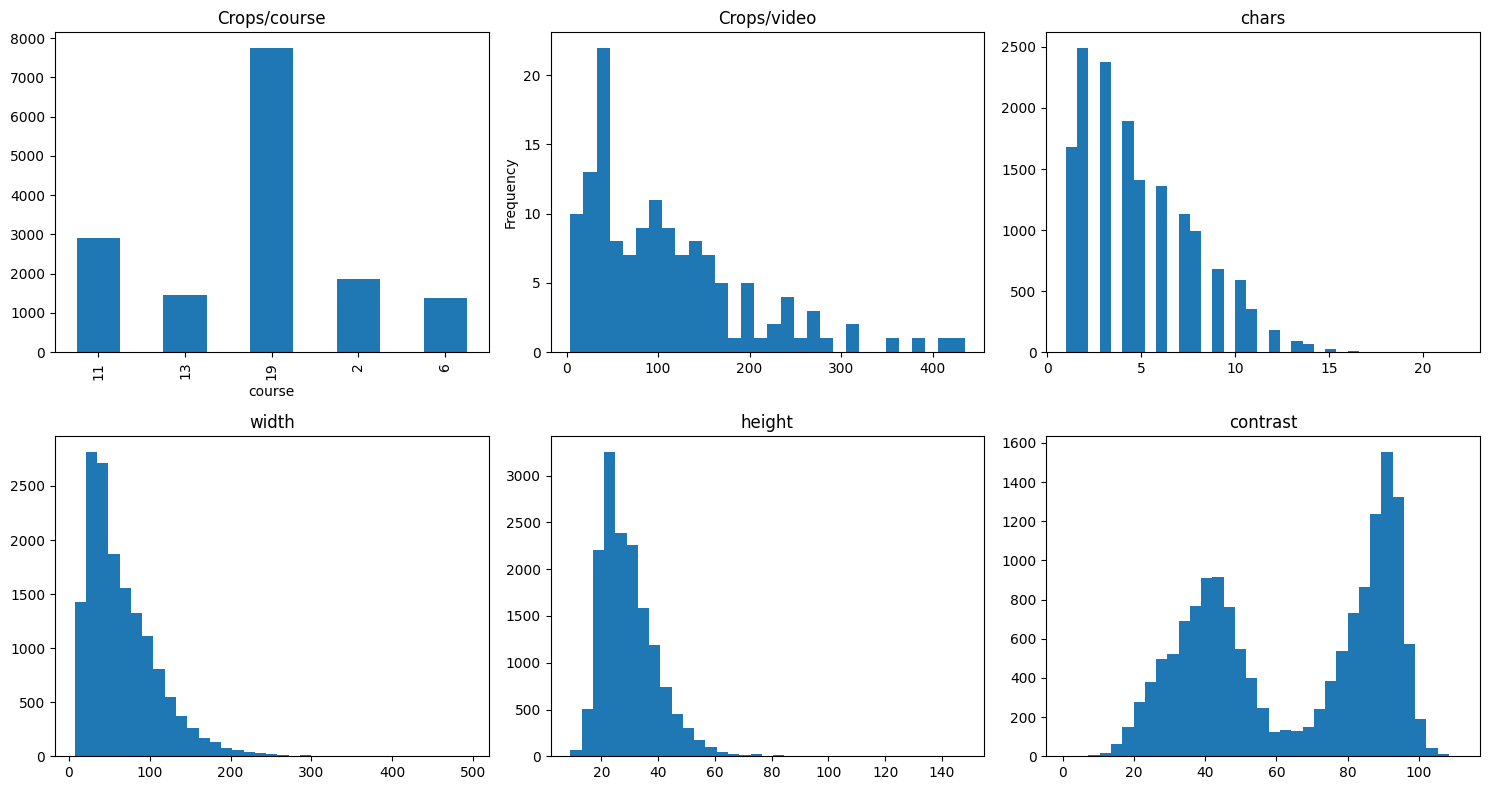

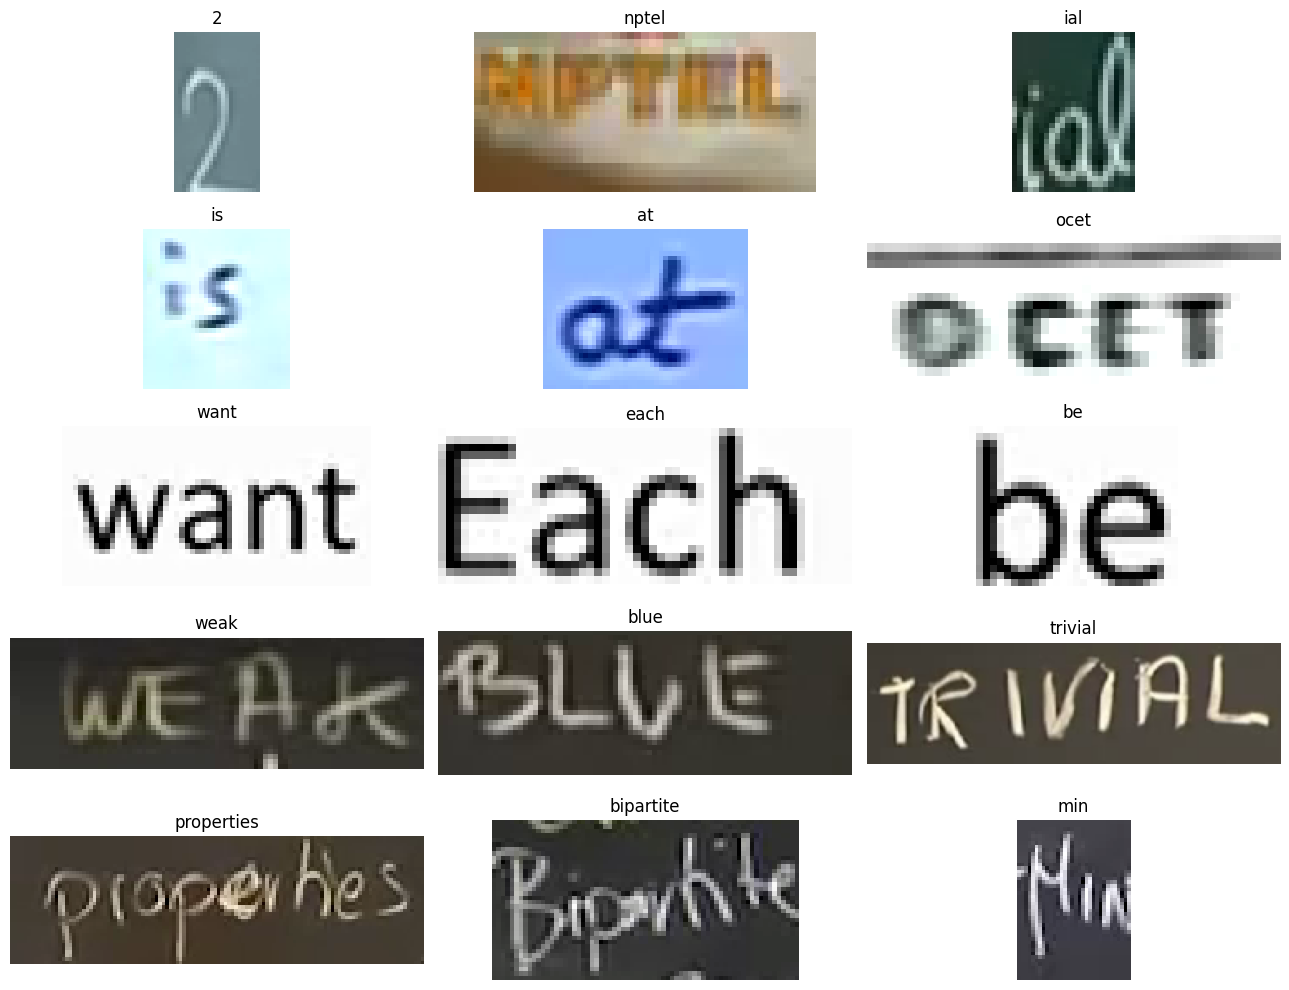

In [4]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
FLAGGED_IDS = ['Crops/val/13/10/99.png', 'Crops/val/13/11/118.png', 'Crops/val/13/18/324.png', 'Crops/val/13/18/328.png', 'Crops/val/13/18/340.png', 'Crops/val/13/18/356.png', 'Crops/val/13/18/361.png', 'Crops/val/13/20/599.png', 'Crops/val/13/3/839.png', 'Crops/val/13/4/862.png', 'Crops/val/13/6/1214.png', 'Crops/val/19/1/118.png', 'Crops/val/19/1/121.png', 'Crops/val/19/1/131.png', 'Crops/val/19/1/16.png', 'Crops/val/19/1/82.png', 'Crops/val/19/1/9.png', 'Crops/val/19/10/299.png', 'Crops/val/19/11/420.png', 'Crops/val/19/11/445.png', 'Crops/val/19/11/459.png', 'Crops/val/19/11/526.png', 'Crops/val/19/11/542.png', 'Crops/val/19/11/549.png', 'Crops/val/19/11/592.png', 'Crops/val/19/11/600.png', 'Crops/val/19/11/602.png', 'Crops/val/19/11/609.png', 'Crops/val/19/12/692.png', 'Crops/val/19/12/701.png', 'Crops/val/19/12/711.png', 'Crops/val/19/12/716.png', 'Crops/val/19/12/723.png', 'Crops/val/19/12/751.png', 'Crops/val/19/13/763.png', 'Crops/val/19/13/770.png', 'Crops/val/19/13/781.png', 'Crops/val/19/13/782.png', 'Crops/val/19/13/801.png', 'Crops/val/19/13/812.png', 'Crops/val/19/13/839.png', 'Crops/val/19/13/843.png', 'Crops/val/19/14/865.png', 'Crops/val/19/14/886.png', 'Crops/val/19/14/906.png', 'Crops/val/19/14/911.png', 'Crops/val/19/14/914.png', 'Crops/val/19/14/917.png', 'Crops/val/19/14/919.png', 'Crops/val/19/14/927.png', 'Crops/val/19/15/1006.png', 'Crops/val/19/15/1012.png', 'Crops/val/19/15/1044.png', 'Crops/val/19/15/1045.png', 'Crops/val/19/15/1049.png', 'Crops/val/19/15/1050.png', 'Crops/val/19/15/1053.png', 'Crops/val/19/15/1058.png', 'Crops/val/19/15/1096.png', 'Crops/val/19/15/1108.png', 'Crops/val/19/15/1110.png', 'Crops/val/19/15/1113.png', 'Crops/val/19/15/966.png', 'Crops/val/19/15/972.png', 'Crops/val/19/15/983.png', 'Crops/val/19/15/999.png', 'Crops/val/19/16/1143.png', 'Crops/val/19/16/1146.png', 'Crops/val/19/16/1147.png', 'Crops/val/19/16/1156.png', 'Crops/val/19/16/1163.png', 'Crops/val/19/16/1165.png', 'Crops/val/19/16/1193.png', 'Crops/val/19/16/1199.png', 'Crops/val/19/16/1205.png', 'Crops/val/19/16/1222.png', 'Crops/val/19/16/1223.png', 'Crops/val/19/16/1250.png', 'Crops/val/19/16/1276.png', 'Crops/val/19/17/1345.png', 'Crops/val/19/17/1425.png', 'Crops/val/19/17/1430.png', 'Crops/val/19/17/1431.png', 'Crops/val/19/17/1434.png', 'Crops/val/19/19/1468.png', 'Crops/val/19/19/1476.png', 'Crops/val/19/19/1480.png', 'Crops/val/19/19/1481.png', 'Crops/val/19/19/1482.png', 'Crops/val/19/19/1503.png', 'Crops/val/19/19/1550.png', 'Crops/val/19/19/1556.png', 'Crops/val/19/2/1569.png', 'Crops/val/19/2/1585.png', 'Crops/val/19/2/1610.png', 'Crops/val/19/2/1665.png', 'Crops/val/19/2/1672.png', 'Crops/val/19/2/1675.png', 'Crops/val/19/2/1698.png', 'Crops/val/19/2/1710.png', 'Crops/val/19/2/1730.png', 'Crops/val/19/2/1744.png', 'Crops/val/19/2/1747.png', 'Crops/val/19/2/1763.png', 'Crops/val/19/2/1776.png', 'Crops/val/19/2/1778.png', 'Crops/val/19/2/1790.png', 'Crops/val/19/20/1818.png', 'Crops/val/19/20/1819.png', 'Crops/val/19/20/1824.png', 'Crops/val/19/20/1827.png', 'Crops/val/19/20/1832.png', 'Crops/val/19/20/1839.png', 'Crops/val/19/20/1840.png', 'Crops/val/19/20/1851.png', 'Crops/val/19/20/1890.png', 'Crops/val/19/20/1899.png', 'Crops/val/19/20/1901.png', 'Crops/val/19/20/1909.png', 'Crops/val/19/20/1934.png', 'Crops/val/19/21/1969.png', 'Crops/val/19/21/1970.png', 'Crops/val/19/21/1975.png', 'Crops/val/19/21/1978.png', 'Crops/val/19/21/1980.png', 'Crops/val/19/21/1984.png', 'Crops/val/19/21/1985.png', 'Crops/val/19/21/1989.png', 'Crops/val/19/21/1995.png', 'Crops/val/19/21/2014.png', 'Crops/val/19/21/2017.png', 'Crops/val/19/21/2022.png', 'Crops/val/19/21/2034.png', 'Crops/val/19/21/2045.png', 'Crops/val/19/21/2089.png', 'Crops/val/19/21/2104.png', 'Crops/val/19/21/2105.png', 'Crops/val/19/21/2108.png', 'Crops/val/19/21/2134.png', 'Crops/val/19/22/2150.png', 'Crops/val/19/22/2158.png', 'Crops/val/19/22/2173.png', 'Crops/val/19/22/2175.png', 'Crops/val/19/22/2182.png', 'Crops/val/19/22/2186.png', 'Crops/val/19/22/2201.png', 'Crops/val/19/22/2218.png', 'Crops/val/19/22/2220.png', 'Crops/val/19/22/2237.png', 'Crops/val/19/22/2240.png', 'Crops/val/19/22/2247.png', 'Crops/val/19/22/2251.png', 'Crops/val/19/22/2261.png', 'Crops/val/19/22/2266.png', 'Crops/val/19/22/2276.png', 'Crops/val/19/22/2295.png', 'Crops/val/19/22/2308.png', 'Crops/val/19/22/2327.png', 'Crops/val/19/22/2333.png', 'Crops/val/19/23/2364.png', 'Crops/val/19/23/2369.png', 'Crops/val/19/23/2417.png', 'Crops/val/19/23/2426.png', 'Crops/val/19/23/2437.png', 'Crops/val/19/23/2454.png', 'Crops/val/19/23/2465.png', 'Crops/val/19/23/2466.png', 'Crops/val/19/23/2473.png', 'Crops/val/19/24/2500.png', 'Crops/val/19/24/2527.png', 'Crops/val/19/24/2535.png', 'Crops/val/19/24/2541.png', 'Crops/val/19/24/2560.png', 'Crops/val/19/24/2564.png', 'Crops/val/19/24/2586.png', 'Crops/val/19/24/2601.png', 'Crops/val/19/24/2616.png', 'Crops/val/19/24/2623.png', 'Crops/val/19/24/2625.png', 'Crops/val/19/24/2631.png', 'Crops/val/19/24/2640.png', 'Crops/val/19/25/2675.png', 'Crops/val/19/25/2686.png', 'Crops/val/19/25/2687.png', 'Crops/val/19/25/2697.png', 'Crops/val/19/25/2739.png', 'Crops/val/19/25/2773.png', 'Crops/val/19/25/2797.png', 'Crops/val/19/25/2801.png', 'Crops/val/19/25/2812.png', 'Crops/val/19/25/2816.png', 'Crops/val/19/25/2840.png', 'Crops/val/19/25/2864.png', 'Crops/val/19/26/2928.png', 'Crops/val/19/26/2960.png', 'Crops/val/19/26/2968.png', 'Crops/val/19/26/2984.png', 'Crops/val/19/26/2996.png', 'Crops/val/19/26/3001.png', 'Crops/val/19/26/3003.png', 'Crops/val/19/27/3020.png', 'Crops/val/19/27/3042.png', 'Crops/val/19/27/3051.png', 'Crops/val/19/27/3063.png', 'Crops/val/19/27/3079.png', 'Crops/val/19/27/3080.png', 'Crops/val/19/27/3088.png', 'Crops/val/19/27/3093.png', 'Crops/val/19/27/3169.png', 'Crops/val/19/28/3196.png', 'Crops/val/19/28/3199.png', 'Crops/val/19/28/3203.png', 'Crops/val/19/28/3204.png', 'Crops/val/19/28/3217.png', 'Crops/val/19/28/3223.png', 'Crops/val/19/28/3224.png', 'Crops/val/19/28/3237.png', 'Crops/val/19/28/3256.png', 'Crops/val/19/29/3289.png', 'Crops/val/19/29/3298.png', 'Crops/val/19/29/3323.png', 'Crops/val/19/29/3338.png', 'Crops/val/19/29/3359.png', 'Crops/val/19/29/3375.png', 'Crops/val/19/29/3377.png', 'Crops/val/19/29/3378.png', 'Crops/val/19/29/3383.png', 'Crops/val/19/3/3428.png', 'Crops/val/19/3/3439.png', 'Crops/val/19/3/3446.png', 'Crops/val/19/3/3452.png', 'Crops/val/19/3/3458.png', 'Crops/val/19/3/3481.png', 'Crops/val/19/3/3486.png', 'Crops/val/19/3/3487.png', 'Crops/val/19/3/3514.png', 'Crops/val/19/3/3524.png', 'Crops/val/19/3/3530.png', 'Crops/val/19/3/3531.png', 'Crops/val/19/3/3532.png', 'Crops/val/19/3/3542.png', 'Crops/val/19/3/3543.png', 'Crops/val/19/30/3565.png', 'Crops/val/19/30/3613.png', 'Crops/val/19/30/3621.png', 'Crops/val/19/30/3622.png', 'Crops/val/19/30/3648.png', 'Crops/val/19/30/3655.png', 'Crops/val/19/30/3670.png', 'Crops/val/19/30/3672.png', 'Crops/val/19/30/3720.png', 'Crops/val/19/30/3746.png', 'Crops/val/19/30/3772.png', 'Crops/val/19/30/3775.png', 'Crops/val/19/30/3790.png', 'Crops/val/19/30/3796.png', 'Crops/val/19/30/3805.png', 'Crops/val/19/30/3821.png', 'Crops/val/19/30/3830.png', 'Crops/val/19/30/3847.png', 'Crops/val/19/30/3858.png', 'Crops/val/19/30/3890.png', 'Crops/val/19/30/3909.png', 'Crops/val/19/30/3922.png', 'Crops/val/19/30/3929.png', 'Crops/val/19/30/3931.png', 'Crops/val/19/30/3934.png', 'Crops/val/19/31/3963.png', 'Crops/val/19/31/4015.png', 'Crops/val/19/31/4024.png', 'Crops/val/19/31/4026.png', 'Crops/val/19/31/4032.png', 'Crops/val/19/31/4033.png', 'Crops/val/19/31/4067.png', 'Crops/val/19/31/4077.png', 'Crops/val/19/31/4102.png', 'Crops/val/19/31/4132.png', 'Crops/val/19/31/4133.png', 'Crops/val/19/31/4142.png', 'Crops/val/19/31/4157.png', 'Crops/val/19/31/4158.png', 'Crops/val/19/32/4210.png', 'Crops/val/19/32/4218.png', 'Crops/val/19/32/4227.png', 'Crops/val/19/32/4276.png', 'Crops/val/19/32/4282.png', 'Crops/val/19/32/4295.png', 'Crops/val/19/32/4306.png', 'Crops/val/19/32/4308.png', 'Crops/val/19/32/4314.png', 'Crops/val/19/32/4338.png', 'Crops/val/19/32/4347.png', 'Crops/val/19/32/4348.png', 'Crops/val/19/32/4349.png', 'Crops/val/19/32/4352.png', 'Crops/val/19/32/4353.png', 'Crops/val/19/32/4355.png', 'Crops/val/19/32/4360.png', 'Crops/val/19/32/4388.png', 'Crops/val/19/32/4390.png', 'Crops/val/19/32/4406.png', 'Crops/val/19/32/4418.png', 'Crops/val/19/32/4426.png', 'Crops/val/19/32/4438.png', 'Crops/val/19/32/4440.png', 'Crops/val/19/32/4442.png', 'Crops/val/19/32/4445.png', 'Crops/val/19/33/4470.png', 'Crops/val/19/33/4489.png', 'Crops/val/19/33/4525.png', 'Crops/val/19/33/4535.png', 'Crops/val/19/33/4598.png', 'Crops/val/19/34/4630.png', 'Crops/val/19/34/4637.png', 'Crops/val/19/34/4684.png', 'Crops/val/19/34/4685.png', 'Crops/val/19/34/4686.png', 'Crops/val/19/34/4716.png', 'Crops/val/19/34/4734.png', 'Crops/val/19/34/4783.png', 'Crops/val/19/34/4826.png', 'Crops/val/19/34/4835.png', 'Crops/val/19/34/4850.png', 'Crops/val/19/34/4852.png', 'Crops/val/19/34/4853.png', 'Crops/val/19/34/4856.png', 'Crops/val/19/34/4859.png', 'Crops/val/19/34/4873.png', 'Crops/val/19/34/4875.png', 'Crops/val/19/34/4891.png', 'Crops/val/19/34/4914.png', 'Crops/val/19/34/4915.png', 'Crops/val/19/34/4916.png', 'Crops/val/19/34/4920.png', 'Crops/val/19/34/4930.png', 'Crops/val/19/34/4962.png', 'Crops/val/19/34/4968.png', 'Crops/val/19/35/5007.png', 'Crops/val/19/35/5013.png', 'Crops/val/19/35/5036.png', 'Crops/val/19/35/5039.png', 'Crops/val/19/35/5047.png', 'Crops/val/19/35/5050.png', 'Crops/val/19/35/5131.png', 'Crops/val/19/36/5157.png', 'Crops/val/19/36/5166.png', 'Crops/val/19/36/5187.png', 'Crops/val/19/36/5196.png', 'Crops/val/19/36/5198.png', 'Crops/val/19/36/5232.png', 'Crops/val/19/36/5259.png', 'Crops/val/19/36/5294.png', 'Crops/val/19/36/5319.png', 'Crops/val/19/37/5341.png', 'Crops/val/19/37/5348.png', 'Crops/val/19/37/5356.png', 'Crops/val/19/37/5359.png', 'Crops/val/19/37/5361.png', 'Crops/val/19/37/5363.png', 'Crops/val/19/37/5367.png', 'Crops/val/19/37/5368.png', 'Crops/val/19/37/5392.png', 'Crops/val/19/37/5406.png', 'Crops/val/19/37/5408.png', 'Crops/val/19/37/5453.png', 'Crops/val/19/37/5454.png', 'Crops/val/19/37/5511.png', 'Crops/val/19/37/5519.png', 'Crops/val/19/37/5521.png', 'Crops/val/19/37/5525.png', 'Crops/val/19/37/5533.png', 'Crops/val/19/37/5534.png', 'Crops/val/19/37/5535.png', 'Crops/val/19/37/5555.png', 'Crops/val/19/37/5566.png', 'Crops/val/19/37/5576.png', 'Crops/val/19/38/5604.png', 'Crops/val/19/38/5611.png', 'Crops/val/19/38/5636.png', 'Crops/val/19/38/5651.png', 'Crops/val/19/38/5659.png', 'Crops/val/19/38/5665.png', 'Crops/val/19/38/5687.png', 'Crops/val/19/38/5697.png', 'Crops/val/19/38/5698.png', 'Crops/val/19/38/5700.png', 'Crops/val/19/39/5738.png', 'Crops/val/19/39/5748.png', 'Crops/val/19/39/5786.png', 'Crops/val/19/39/5824.png', 'Crops/val/19/39/5847.png', 'Crops/val/19/39/5860.png', 'Crops/val/19/4/5931.png', 'Crops/val/19/4/5935.png', 'Crops/val/19/4/5939.png', 'Crops/val/19/4/5943.png', 'Crops/val/19/4/5946.png', 'Crops/val/19/4/5966.png', 'Crops/val/19/4/5972.png', 'Crops/val/19/4/5973.png', 'Crops/val/19/4/5990.png', 'Crops/val/19/4/6004.png', 'Crops/val/19/4/6009.png', 'Crops/val/19/4/6017.png', 'Crops/val/19/4/6056.png', 'Crops/val/19/4/6058.png', 'Crops/val/19/4/6061.png', 'Crops/val/19/4/6070.png', 'Crops/val/19/4/6073.png', 'Crops/val/19/4/6074.png', 'Crops/val/19/4/6078.png', 'Crops/val/19/4/6083.png', 'Crops/val/19/4/6089.png', 'Crops/val/19/4/6091.png', 'Crops/val/19/4/6092.png', 'Crops/val/19/4/6094.png', 'Crops/val/19/4/6111.png', 'Crops/val/19/4/6113.png', 'Crops/val/19/4/6128.png', 'Crops/val/19/4/6129.png', 'Crops/val/19/4/6139.png', 'Crops/val/19/4/6141.png', 'Crops/val/19/4/6151.png', 'Crops/val/19/4/6168.png', 'Crops/val/19/4/6182.png', 'Crops/val/19/4/6188.png', 'Crops/val/19/40/6204.png', 'Crops/val/19/40/6228.png', 'Crops/val/19/40/6238.png', 'Crops/val/19/40/6266.png', 'Crops/val/19/40/6274.png', 'Crops/val/19/40/6281.png', 'Crops/val/19/40/6283.png', 'Crops/val/19/40/6285.png', 'Crops/val/19/41/6319.png', 'Crops/val/19/41/6327.png', 'Crops/val/19/41/6330.png', 'Crops/val/19/41/6349.png', 'Crops/val/19/41/6350.png', 'Crops/val/19/41/6372.png', 'Crops/val/19/41/6384.png', 'Crops/val/19/41/6388.png', 'Crops/val/19/41/6389.png', 'Crops/val/19/41/6406.png', 'Crops/val/19/41/6416.png', 'Crops/val/19/41/6420.png', 'Crops/val/19/41/6435.png', 'Crops/val/19/41/6453.png', 'Crops/val/19/42/6487.png', 'Crops/val/19/42/6493.png', 'Crops/val/19/42/6532.png', 'Crops/val/19/42/6536.png', 'Crops/val/19/42/6537.png', 'Crops/val/19/43/6581.png', 'Crops/val/19/43/6593.png', 'Crops/val/19/43/6599.png', 'Crops/val/19/43/6601.png', 'Crops/val/19/43/6612.png', 'Crops/val/19/43/6613.png', 'Crops/val/19/43/6630.png', 'Crops/val/19/43/6631.png', 'Crops/val/19/43/6654.png', 'Crops/val/19/43/6656.png', 'Crops/val/19/43/6676.png', 'Crops/val/19/43/6686.png', 'Crops/val/19/43/6700.png', 'Crops/val/19/43/6710.png', 'Crops/val/19/43/6751.png', 'Crops/val/19/43/6763.png', 'Crops/val/19/44/6798.png', 'Crops/val/19/44/6855.png', 'Crops/val/19/45/6988.png', 'Crops/val/19/46/7003.png', 'Crops/val/19/46/7027.png', 'Crops/val/19/46/7030.png', 'Crops/val/19/46/7053.png', 'Crops/val/19/46/7064.png', 'Crops/val/19/5/7105.png', 'Crops/val/19/5/7132.png', 'Crops/val/19/5/7135.png', 'Crops/val/19/5/7151.png', 'Crops/val/19/5/7164.png', 'Crops/val/19/5/7167.png', 'Crops/val/19/5/7171.png', 'Crops/val/19/5/7175.png', 'Crops/val/19/5/7184.png', 'Crops/val/19/5/7186.png', 'Crops/val/19/5/7226.png', 'Crops/val/19/5/7236.png', 'Crops/val/19/5/7244.png', 'Crops/val/19/5/7265.png', 'Crops/val/19/5/7282.png', 'Crops/val/19/6/7320.png', 'Crops/val/19/6/7321.png', 'Crops/val/19/6/7329.png', 'Crops/val/19/6/7332.png', 'Crops/val/19/6/7334.png', 'Crops/val/19/6/7336.png', 'Crops/val/19/6/7338.png', 'Crops/val/19/6/7376.png', 'Crops/val/19/6/7378.png', 'Crops/val/19/6/7380.png', 'Crops/val/19/6/7384.png', 'Crops/val/19/6/7395.png', 'Crops/val/19/7/7417.png', 'Crops/val/19/7/7418.png', 'Crops/val/19/7/7424.png', 'Crops/val/19/7/7426.png', 'Crops/val/19/7/7439.png', 'Crops/val/19/7/7482.png', 'Crops/val/19/7/7483.png', 'Crops/val/19/7/7497.png', 'Crops/val/19/7/7504.png', 'Crops/val/19/7/7518.png', 'Crops/val/19/7/7544.png', 'Crops/val/19/7/7547.png', 'Crops/val/19/7/7554.png', 'Crops/val/19/7/7555.png', 'Crops/val/19/7/7564.png', 'Crops/val/19/7/7567.png', 'Crops/val/19/7/7577.png', 'Crops/val/19/7/7578.png', 'Crops/val/19/7/7579.png', 'Crops/val/19/7/7582.png', 'Crops/val/19/7/7591.png', 'Crops/val/19/8/7609.png', 'Crops/val/19/8/7630.png', 'Crops/val/19/9/7644.png', 'Crops/val/19/9/7650.png', 'Crops/val/19/9/7664.png', 'Crops/val/19/9/7682.png', 'Crops/val/19/9/7683.png', 'Crops/val/19/9/7695.png', 'Crops/val/19/9/7699.png', 'Crops/val/19/9/7701.png', 'Crops/val/19/9/7702.png', 'Crops/val/19/9/7736.png']
rows = []
for crop_id, path, label in cohort:
    with Image.open(path) as image:
        gray = np.asarray(image.convert('L'))
        width, height = image.size
    parts = crop_id.split('/')
    rows.append(dict(crop_id=crop_id, course=parts[2], video='/'.join(parts[2:4]),
                     label=label, chars=len(normalize(label)), width=width, height=height,
                     contrast=float(gray.std()), has_digit=any(c.isdigit() for c in label),
                     punctuation=any(not c.isalnum() and not c.isspace() for c in label),
                     review_flag=crop_id in FLAGGED_IDS))
features = pd.DataFrame(rows)
assert features.crop_id.is_unique and features.review_flag.sum() == 537
assert (features[['width', 'height', 'chars']] > 0).all().all()
features.to_csv(OUT / 'cohort-features.csv', index=False)
display(features.groupby('course').agg(crops=('crop_id','size'), videos=('video','nunique')))
display(features[['chars','width','height','contrast']].describe())
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
features.groupby('course').size().plot.bar(ax=axes[0,0], title='Crops/course')
features.groupby('video').size().plot.hist(ax=axes[0,1], bins=30, title='Crops/video')
for ax, name in zip([axes[0,2], *axes[1]], ['chars','width','height','contrast']):
    ax.hist(features[name], bins=35); ax.set_title(name)
fig.tight_layout(); fig.savefig(OUT / 'eda-distributions.png'); plt.show()
sample = pd.concat([group.sort_values(['contrast','crop_id']).iloc[
    [int((len(group)-1)*q) for q in (0.1,0.5,0.9)]]
    for _, group in features.groupby('course')])
fig, axes = plt.subplots(5,3,figsize=(13,10))
for ax, (idx,row) in zip(axes.flat, sample.iterrows()):
    ax.imshow(Image.open(DATA/row.crop_id)); ax.set_title(row.label); ax.axis('off')
fig.tight_layout(); fig.savefig(OUT/'eda-crop-gallery.png'); plt.show()


## Môi trường CPU riêng và trọng số

Chạy tuần tự, mỗi thư viện 1 CPU thread. Cấu hình batch của mỗi engine giữ theo runner lịch sử (EasyOCR 1, PaddleOCR 32). Notebook ghi thời gian phiên để vận hành, không dùng nó để kết luận tốc độ engine; resume và môi trường Colab có thể thay đổi tài nguyên. Không tự lấy model thay thế nếu hash sai.


In [5]:
ENV = WORK / 'ocr-py311'
subprocess.run([sys.executable, '-m', 'uv', 'venv', '--python', '3.11',
                '--python-preference', 'only-managed', str(ENV), '--allow-existing'], check=True)
PY = ENV / ('Scripts/python.exe' if os.name == 'nt' else 'bin/python')
subprocess.run([sys.executable, '-m', 'uv', 'pip', 'install', '--python', str(PY),
    'torch==2.5.1', 'torchvision==0.20.1', '--index-url',
    'https://download.pytorch.org/whl/cpu'], check=True)
subprocess.run([sys.executable, '-m', 'uv', 'pip', 'install', '--python', str(PY),
    'setuptools==75.8.0', 'numpy==1.26.4', 'paddlepaddle==2.6.2', 'paddleocr==2.8.1',
    'easyocr==1.7.2', 'opencv-python==4.6.0.66',
    'opencv-contrib-python==4.6.0.66', 'opencv-python-headless==4.6.0.66'], check=True)
CHILD_ENV = dict(os.environ, OMP_NUM_THREADS='1', MKL_NUM_THREADS='1',
                 OPENBLAS_NUM_THREADS='1', CUDA_VISIBLE_DEVICES='')
setup = "from pathlib import Path\nprint('Preflight stage: importing OCR libraries', flush=True)\nimport easyocr, paddleocr, paddle, torch, sys\nroot = Path(sys.argv[1])\ntorch.set_num_threads(1)\nprint('Preflight stage: loading EasyOCR recognition weights', flush=True)\neasyocr.Reader(['en'], gpu=False, detector=False, recognizer=True,\n               model_storage_directory=str(root/'easyocr'), download_enabled=True, verbose=False)\nprint('Preflight stage: loading PaddleOCR recognition weights', flush=True)\npaddleocr.PaddleOCR(use_angle_cls=False, lang='en', det=False, rec=True, use_gpu=False,\n                   show_log=False, cpu_threads=1, ocr_version='PP-OCRv4',\n                   rec_model_dir=str(root/'paddleocr/en_PP-OCRv4_rec_infer'))\nprint('Installed engines:', easyocr.__version__, paddleocr.__version__, flush=True)\nassert easyocr.__version__ == '1.7.2' and paddleocr.__version__ == '2.8.1'\nprint('Preflight:', sys.version, paddle.__version__, torch.__version__)\nimport numpy as np\nfrom PIL import Image\nfrom experiments.scripts.ocr_comparison_runtime import verify_models, load_engine\nfrom experiments.scripts.ocr_validation_recognition import load_cohort\ncohort = load_cohort(Path(sys.argv[2]))\nwith Image.open(cohort[0][1]) as image:\n    pixels = np.asarray(image.convert('RGB'))\nfor engine in ('easyocr_cpu','paddleocr'):\n    print('Preflight stage: model hash and one-crop inference:', engine, flush=True)\n    verify_models(engine, root)\n    predictor, engine_version, batch = load_engine(engine, root)\n    output = predictor([pixels])\n    assert len(output) == 1 and isinstance(output[0], str), (engine, output)\n    print('Inference preflight passed:', engine, engine_version)\n"
lock = subprocess.check_output([sys.executable, '-m', 'uv', 'pip', 'freeze',
                               '--python', str(PY)], text=True)
(OUT/'installed-packages.txt').write_text(lock)

def run_logged(command, log_path, cwd, env):
    # Merge stderr into stdout so the real child traceback is visible and persisted.
    with log_path.open('w', encoding='utf-8') as log:
        with subprocess.Popen(command, cwd=cwd, env=env, stdout=subprocess.PIPE,
                              stderr=subprocess.STDOUT, text=True, encoding='utf-8',
                              errors='replace', bufsize=1) as process:
            try:
                for line in process.stdout:
                    print(line, end='', flush=True)
                    log.write(line); log.flush()
                returncode = process.wait()
            except BaseException:
                process.terminate()
                try:
                    process.wait(timeout=5)
                except subprocess.TimeoutExpired:
                    process.kill(); process.wait()
                raise
    if returncode:
        raise RuntimeError(f'OCR preflight failed (exit {returncode}). The original error is printed above and saved in {log_path}.')

import time
PREFLIGHT_LOG = OUT / f'ocr-preflight-{time.time_ns()}.log'
run_logged([str(PY), '-u', '-c', setup, str(MODEL), str(DATA)],
           PREFLIGHT_LOG, WORK, CHILD_ENV)
print('Preflight log:', PREFLIGHT_LOG)


Preflight stage: importing OCR libraries
Preflight stage: loading EasyOCR recognition weights
[2026-10-13 03:45:53,525] [ WARNING] easyocr.py:176 - Downloading recognition model, please wait. This may take several minutes depending upon your network connection.
Preflight stage: loading PaddleOCR recognition weights
download https://paddleocr.bj.bcebos.com/PP-OCRv3/english/en_PP-OCRv3_det_infer.tar to /root/.paddleocr/whl/det/en/en_PP-OCRv3_det_infer/en_PP-OCRv3_det_infer.tar

  0%|          | 0.00/4.00M [00:00<?, ?iB/s]
  0%|          | 3.07k/4.00M [00:00<04:09, 16.1kiB/s]
  1%|          | 35.8k/4.00M [00:00<00:54, 72.2kiB/s]
  1%|▏         | 52.2k/4.00M [00:00<00:52, 75.9kiB/s]
  2%|▏         | 85.0k/4.00M [00:01<00:46, 84.3kiB/s]
  3%|▎         | 118k/4.00M [00:01<00:40, 95.6kiB/s] 
  3%|▎         | 134k/4.00M [00:01<00:51, 75.0kiB/s]
  4%|▍         | 151k/4.00M [00:02<00:55, 69.3kiB/s]
  4%|▍         | 167k/4.00M [00:02<00:58, 65.1kiB/s]
  5%|▍         | 183k/4.00M [00:02<01:03, 60.

In [6]:
# Rerun this cell after interruption; committed rows are checked and reused.
subprocess.run([str(PY), '-m', 'experiments.scripts.ocr_comparison_runtime',
    '--engine', 'easyocr_cpu', '--dataset-root', str(DATA),
    '--output-root', str(OUT), '--model-root', str(MODEL)],
    cwd=WORK, env=CHILD_ENV, check=True)


CompletedProcess(args=['/content/ocr-comparison/ocr-py311/bin/python', '-m', 'experiments.scripts.ocr_comparison_runtime', '--engine', 'easyocr_cpu', '--dataset-root', '/content/ocr-comparison/IIIT-CVid', '--output-root', '/content/drive/MyDrive/OCR/ocr-validation-261013-v1', '--model-root', '/content/ocr-comparison/models'], returncode=0)

In [7]:
# Rerun this cell after interruption; committed rows are checked and reused.
subprocess.run([str(PY), '-m', 'experiments.scripts.ocr_comparison_runtime',
    '--engine', 'paddleocr', '--dataset-root', str(DATA),
    '--output-root', str(OUT), '--model-root', str(MODEL)],
    cwd=WORK, env=CHILD_ENV, check=True)


CompletedProcess(args=['/content/ocr-comparison/ocr-py311/bin/python', '-m', 'experiments.scripts.ocr_comparison_runtime', '--engine', 'paddleocr', '--dataset-root', '/content/ocr-comparison/IIIT-CVid', '--output-root', '/content/drive/MyDrive/OCR/ocr-validation-261013-v1', '--model-root', '/content/ocr-comparison/models'], returncode=0)

,crops,reference_chars,edit_distance,micro_cer,exact_word_rate,empty_predictions,failures
easyocr,15379.0,73654.0,17999.0,0.244372,0.549386,8.0,0.0
paddleocr,15379.0,73654.0,8630.0,0.117169,0.716757,18.0,0.0


Paddle - Easy CER: -0.12720286746137344
95% paired video-cluster bootstrap: [-0.15584718017561403, -0.09978269965312926]


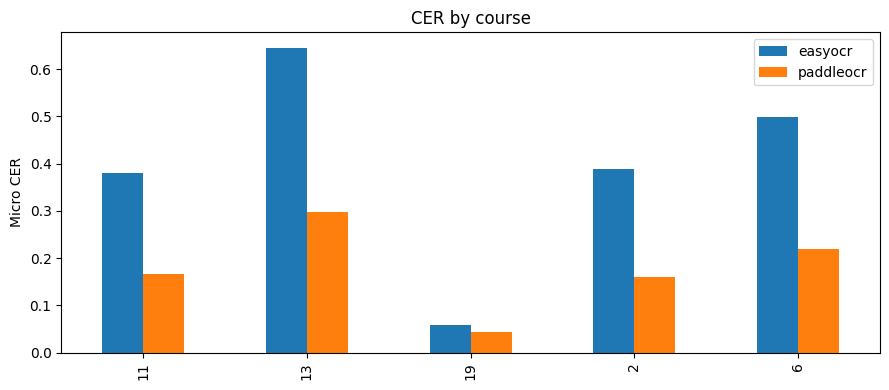

In [8]:
# Refuses partial, duplicate, mixed-source or mismatched reference rows.
subprocess.run([str(PY), '-m', 'experiments.scripts.summarize_ocr_validation',
    '--dataset-root', str(DATA), '--source-archive', str(ARCHIVE),
    '--output-root', str(OUT)], cwd=WORK, env=CHILD_ENV, check=True)
summary = json.loads((OUT/'paired_full.summary.json').read_text())
display(pd.DataFrame({k:summary[k] for k in ['easyocr','paddleocr']}).T)
print('Paddle - Easy CER:', summary['paddle_minus_easy_micro_cer'])
print('95% paired video-cluster bootstrap:', summary['paired_video_bootstrap_95_interval'])
per_course = pd.DataFrame({k:{m:v[m]['micro_cer'] for m in ['easyocr','paddleocr']}
                          for k,v in summary['by_course'].items()}).T
per_course.plot.bar(figsize=(9,4), ylabel='Micro CER', title='CER by course')
plt.tight_layout(); plt.savefig(OUT/'cer-by-course.png'); plt.show()


In [ ]:
from experiments.scripts.summarize_ocr_validation import load, score
refs = {key:label for key, _, label in cohort}
easy = load('easyocr_cpu', OUT, refs); paddle = load('paddleocr', OUT, refs)
paired = features.set_index('crop_id').copy()
for name, records in [('easy', easy), ('paddle', paddle)]:
    paired[name+'_edits'] = pd.Series({k:v['edit_distance'] for k,v in records.items()})
paired['refchars'] = pd.Series({k:v['reference_chars'] for k,v in easy.items()})
paired['length_bin'] = pd.cut(paired.chars, [0,2,5,10,float('inf')])
paired['width_bin'] = pd.cut(paired.width, [0,32,64,128,float('inf')])
paired['contrast_bin'] = pd.cut(paired.contrast, [0,20,40,60,128], include_lowest=True)
for feature in ['length_bin','width_bin','contrast_bin','has_digit','punctuation','review_flag']:
    grouped = paired.groupby(feature, observed=True).agg(
        crops=('refchars','size'), refchars=('refchars','sum'),
        easy_edits=('easy_edits','sum'), paddle_edits=('paddle_edits','sum'))
    grouped['easy_cer'] = grouped.easy_edits/grouped.refchars
    grouped['paddle_cer'] = grouped.paddle_edits/grouped.refchars
    display(grouped)
    grouped.to_csv(OUT/f'error-by-{feature}.csv')
retained = [k for k in easy if k not in FLAGGED_IDS]
display(pd.DataFrame({'easy':score([easy[k] for k in retained]),
                      'paddle':score([paddle[k] for k in retained])}).T)
print('Sensitivity ONLY, not cleaned GT: excludes historical review flags; primary keeps all crops.')
failures = [{**row, 'engine':name} for name,records in [('easy',easy),('paddle',paddle)]
            for row in records.values() if row['error'] is not None]
(OUT/'failure-ledger.json').write_text(json.dumps(failures, ensure_ascii=False, indent=2))
paired.to_csv(OUT/'paired-errors.csv')


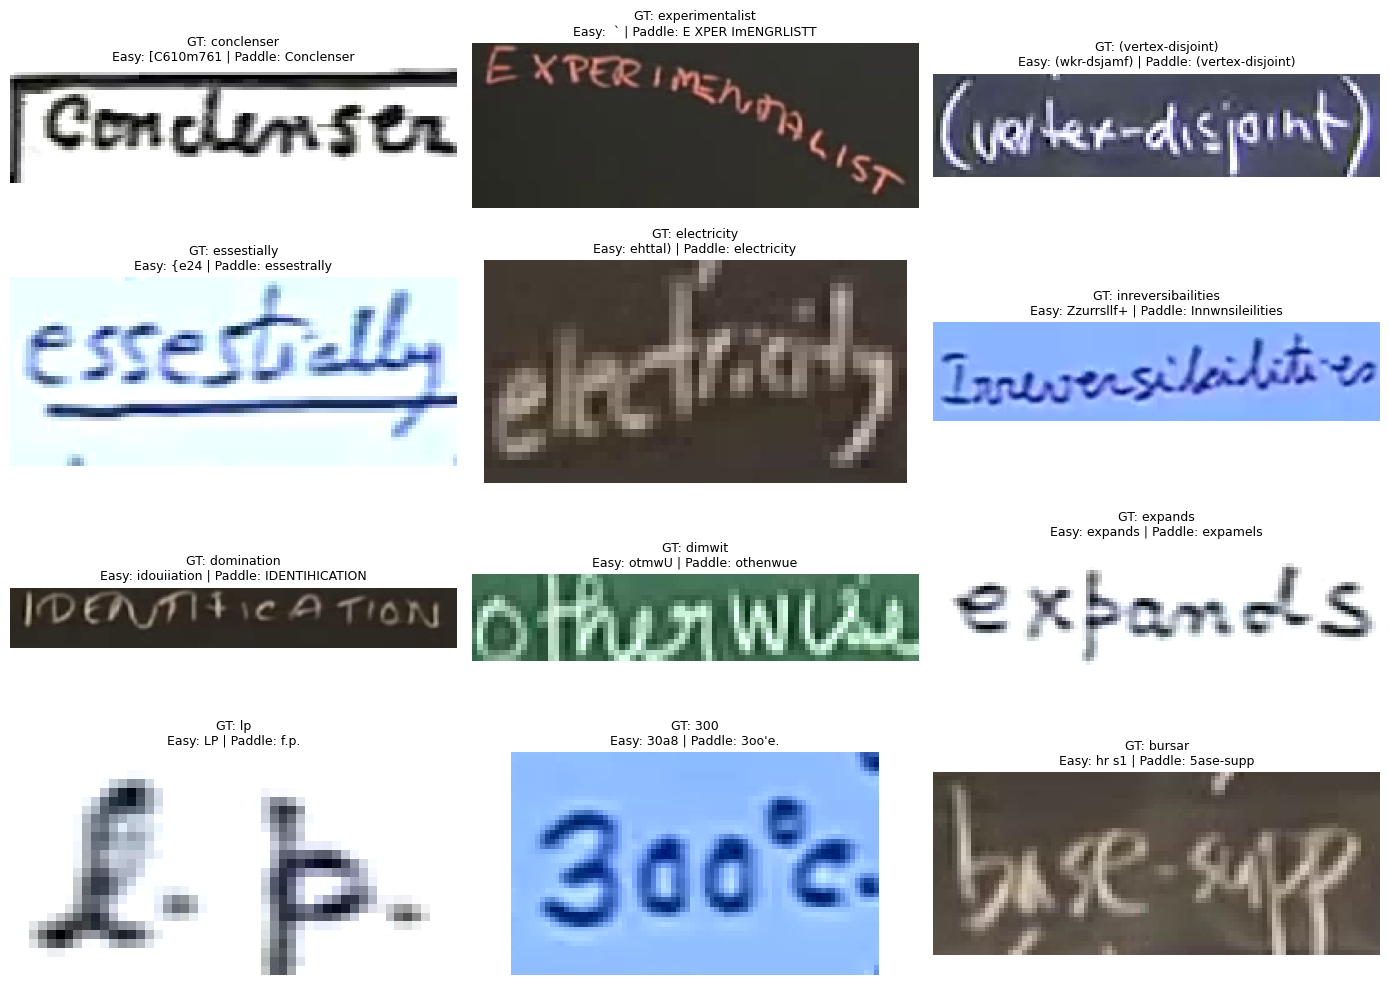

Complete outputs: /content/drive/MyDrive/OCR/ocr-validation-261013-v1
Interpretation: compare overall and course-level CER, interval, failures and label-flag sensitivity.
Scope stays exposed validation crop recognition; no frame detection or unseen-test claim.


In [10]:
# Deterministic examples: largest edit gaps, not random cherry-picked successes.
paired['gap'] = paired.paddle_edits-paired.easy_edits
examples = pd.concat([paired.sort_values(['gap'], kind='stable').head(6),
                      paired.sort_values(['gap'], ascending=False, kind='stable').head(6)])
fig, axes = plt.subplots(4,3,figsize=(14,10))
for ax,(key,row) in zip(axes.flat, examples.iterrows()):
    ax.imshow(Image.open(DATA/key)); ax.axis('off')
    ax.set_title(f"GT: {row.label}\nEasy: {easy[key]['prediction']} | Paddle: {paddle[key]['prediction']}", fontsize=9)
fig.tight_layout(); fig.savefig(OUT/'paired-error-gallery.png'); plt.show()
print('Complete outputs:', OUT)
print('Interpretation: compare overall and course-level CER, interval, failures and label-flag sensitivity.')
print('Scope stays exposed validation crop recognition; no frame detection or unseen-test claim.')


## Bảng và đồ thị phân tích đầy đủ

Hiển thị kết quả tổng thể, bảng đầy đủ 140 video, phân bố CER theo video, paired scatter/delta, 7 nhóm đặc điểm crop, số crop thắng/thua, exact-word agreement, độ nhạy với cờ nhãn và khoảng tin cậy bootstrap. Các bảng xuất CSV và hình xuất PNG vào Drive. Nhóm đặc điểm chỉ mô tả, không xác lập quan hệ nhân quả; nhãn nguồn và cohort chính giữ nguyên.


### Overall scores and coverage — lower CER is better

,crops,reference_chars,edit_distance,micro_cer,exact_word_rate,empty_predictions,failures
EasyOCR,15379,73654,17999,0.244372,0.549386,8,0
PaddleOCR,15379,73654,8630,0.117169,0.716757,18,0


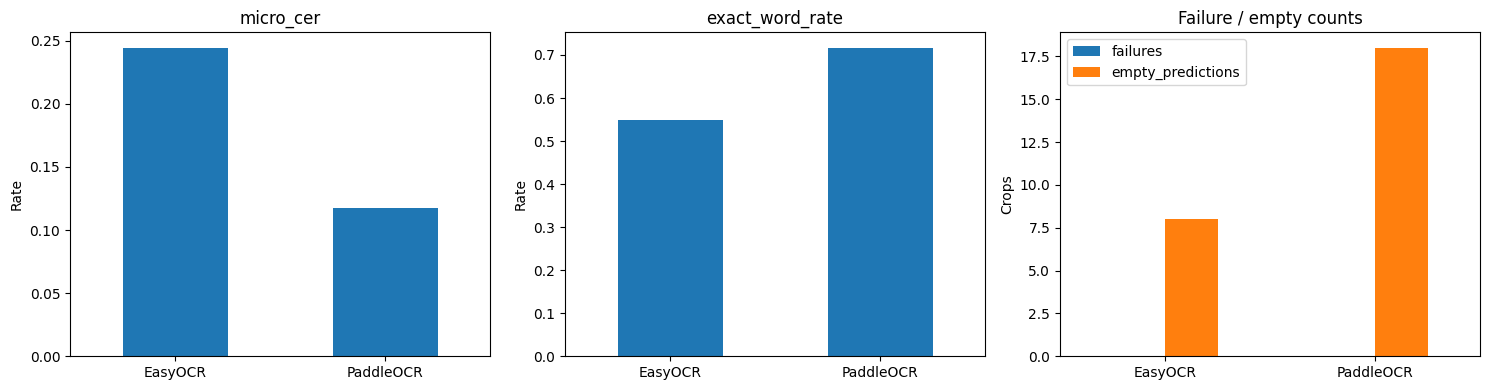

### Per-course and per-video results

,crops,reference_chars,easy_edits,paddle_edits,easy_cer,easy_exact,paddle_cer,paddle_exact,delta_cer
course,,,,,,,,,
11,2907,10820,4111,1800,0.379945,0.394565,0.166359,0.650843,-0.213586
13,1452,7318,4724,2183,0.645532,0.075069,0.298306,0.354683,-0.347226
19,7757,39713,2283,1710,0.057487,0.832281,0.043059,0.887328,-0.014429
2,1875,9080,3525,1460,0.388216,0.261333,0.160793,0.586133,-0.227423
6,1388,6723,3356,1477,0.499182,0.177954,0.219694,0.456772,-0.279488


,crops,reference_chars,easy_edits,paddle_edits,easy_cer,easy_exact,paddle_cer,paddle_exact,delta_cer
count,140.000000,140.000000,140.000000,140.000000,140.000000,140.000000,140.000000,140.000000,140.000000
mean,109.850000,526.100000,128.564286,61.642857,0.323279,0.443464,0.147202,0.655827,-0.176078
std,88.397152,436.696515,158.679497,69.767865,0.228414,0.301485,0.108567,0.225810,0.133150
min,4.000000,30.000000,13.000000,2.000000,0.026455,0.000000,0.010183,0.100000,-0.500000
25%,40.000000,178.250000,42.000000,21.000000,0.074105,0.201042,0.049459,0.491485,-0.274810
50%,93.500000,410.000000,67.500000,37.500000,0.332785,0.372807,0.130789,0.687906,-0.191100
75%,148.250000,755.250000,140.000000,78.750000,0.476106,0.804304,0.214547,0.859144,-0.019938
max,435.000000,2068.000000,955.000000,401.000000,0.875000,0.900621,0.460000,0.963415,-0.002139


,crops,reference_chars,easy_edits,paddle_edits,easy_cer,easy_exact,paddle_cer,paddle_exact,delta_cer
video,,,,,,,,,
11/1,106,384,170,78,0.442708,0.405660,0.203125,0.698113,-0.239583
11/10,39,138,63,26,0.456522,0.333333,0.188406,0.487179,-0.268116
11/11,40,154,73,24,0.474026,0.300000,0.155844,0.650000,-0.318182
11/12,57,228,88,21,0.385965,0.350877,0.092105,0.719298,-0.293860
11/13,25,98,50,20,0.510204,0.240000,0.204082,0.560000,-0.306122
11/14,57,192,64,26,0.333333,0.385965,0.135417,0.666667,-0.197917
11/15,18,97,24,11,0.247423,0.500000,0.113402,0.666667,-0.134021
11/16,76,268,101,37,0.376866,0.368421,0.138060,0.710526,-0.238806
11/17,128,437,187,52,0.427918,0.343750,0.118993,0.703125,-0.308924


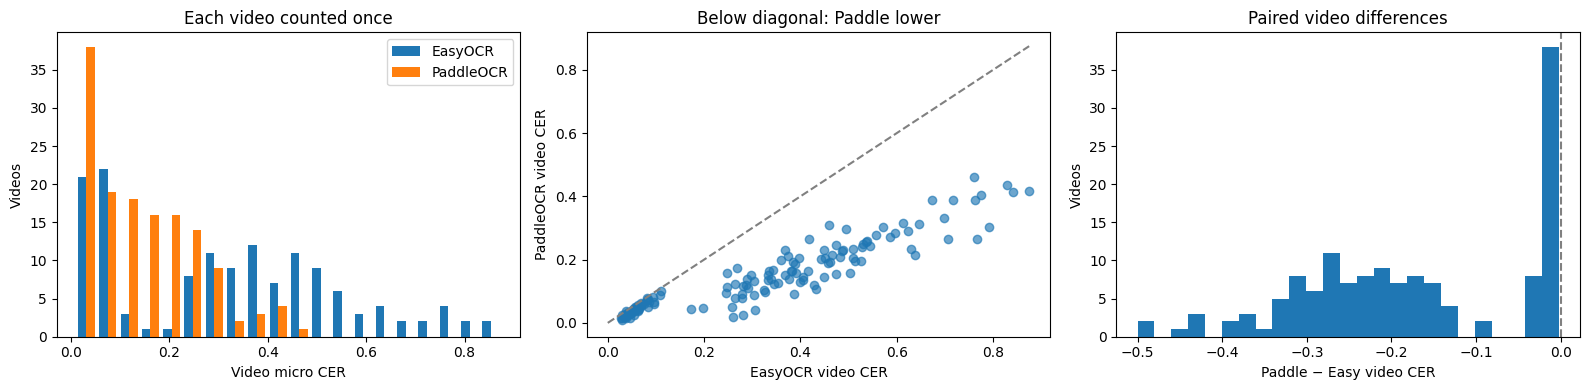

### Feature strata — correlated descriptive groups, not causal effects

**length_bin**

,crops,reference_chars,easy_edits,paddle_edits,easy_cer,easy_exact,paddle_cer,paddle_exact,delta_cer
length_bin,,,,,,,,,
"(-0.001, 2.0]",4179,6674,2057,1136,0.308211,0.644173,0.170213,0.788945,-0.137998
"(2.0, 5.0]",5687,21784,5466,2472,0.250918,0.553895,0.113478,0.748022,-0.137440
"(5.0, 10.0]",4766,36147,8245,3777,0.228096,0.479228,0.104490,0.644356,-0.123606
"(10.0, inf]",747,9049,2231,1245,0.246547,0.432396,0.137584,0.536814,-0.108962


**width_bin**

,crops,reference_chars,easy_edits,paddle_edits,easy_cer,easy_exact,paddle_cer,paddle_exact,delta_cer
width_bin,,,,,,,,,
"(-0.001, 32.0]",3858,6867,2107,1157,0.306830,0.638414,0.168487,0.784603,-0.138343
"(32.0, 64.0]",5244,19347,5201,2475,0.268827,0.565789,0.127927,0.739321,-0.140900
"(64.0, 128.0]",4955,34450,7674,3540,0.222758,0.499697,0.102758,0.672452,-0.120000
"(128.0, inf]",1322,12990,3017,1458,0.232256,0.410741,0.112240,0.595310,-0.120015


**height_bin**

... (5 outputs left out)

**punctuation**

,crops,reference_chars,easy_edits,paddle_edits,easy_cer,easy_exact,paddle_cer,paddle_exact,delta_cer
punctuation,,,,,,,,,
False,14940,71258,17063,8124,0.239454,0.559170,0.114008,0.725368,-0.125446
True,439,2396,936,506,0.390651,0.216401,0.211185,0.423690,-0.179466


**review_flag**

,crops,reference_chars,easy_edits,paddle_edits,easy_cer,easy_exact,paddle_cer,paddle_exact,delta_cer
review_flag,,,,,,,,,
False,14842,71806,17769,8427,0.247458,0.541436,0.117358,0.713718,-0.130101
True,537,1848,230,203,0.124459,0.769088,0.109848,0.800745,-0.014610


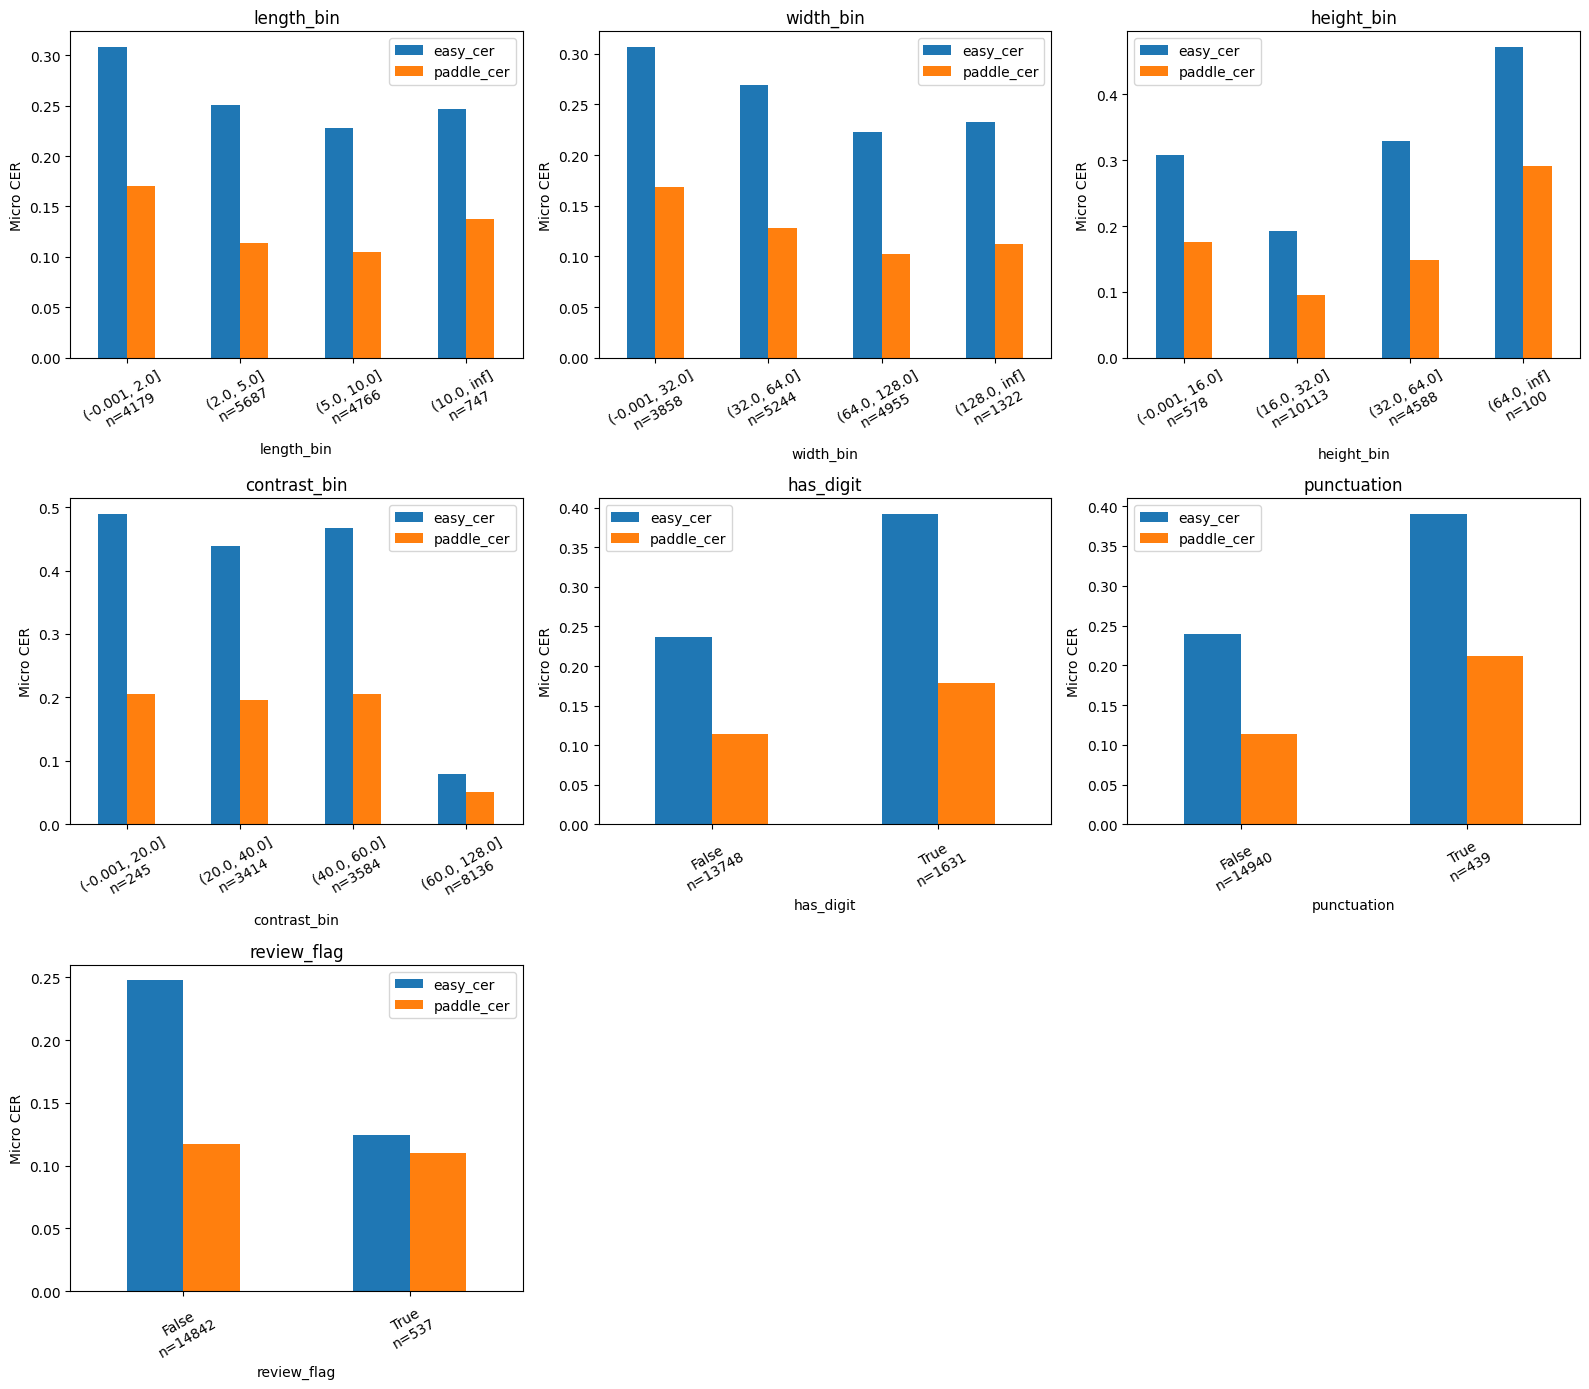

### Paired outcomes: edit distance and exact-word agreement

,crops
Paddle fewer edits,4982
Equal edits,9935
Easy fewer edits,462


,crops
Both exact,8204
Easy only exact,245
Paddle only exact,2819
Neither exact,4111


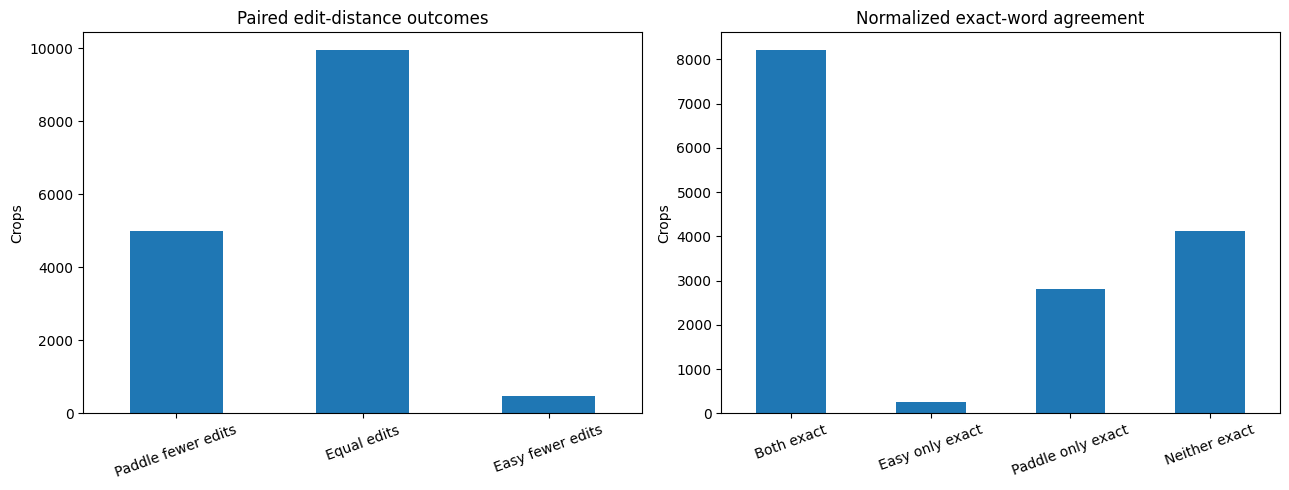

### Review-flag sensitivity — primary includes every crop

,group,engine,crops,reference_chars,edit_distance,micro_cer,exact_word_rate,empty_predictions,failures
0,All crops (primary),EasyOCR,15379,73654,17999,0.244372,0.549386,8,0
1,All crops (primary),PaddleOCR,15379,73654,8630,0.117169,0.716757,18,0
2,Flagged only,EasyOCR,537,1848,230,0.124459,0.769088,0,0
3,Flagged only,PaddleOCR,537,1848,203,0.109848,0.800745,0,0
4,Unflagged only,EasyOCR,14842,71806,17769,0.247458,0.541436,8,0
5,Unflagged only,PaddleOCR,14842,71806,8427,0.117358,0.713718,18,0


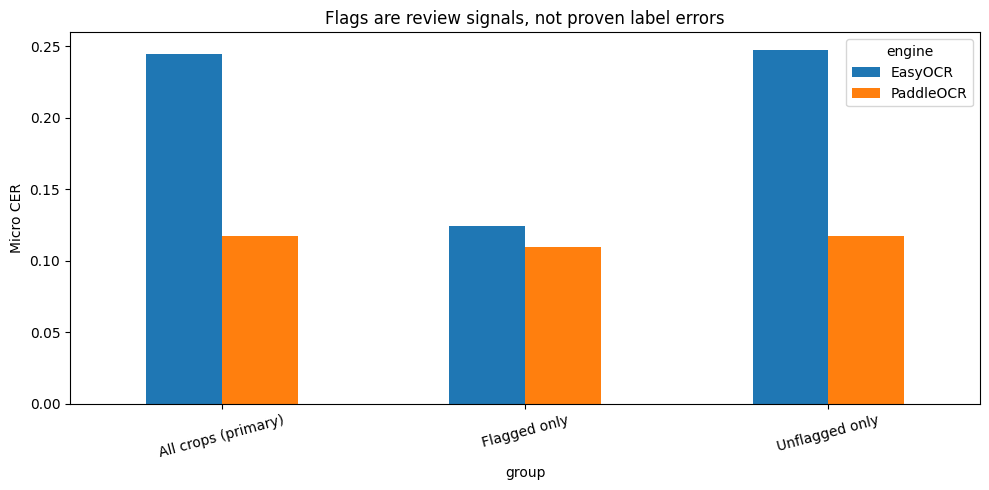

### Paired source-video bootstrap: Paddle − Easy micro CER

,delta_cer,lower_95,upper_95,videos,draws,seed
0,-0.127203,-0.155847,-0.099783,140,2000,20261009


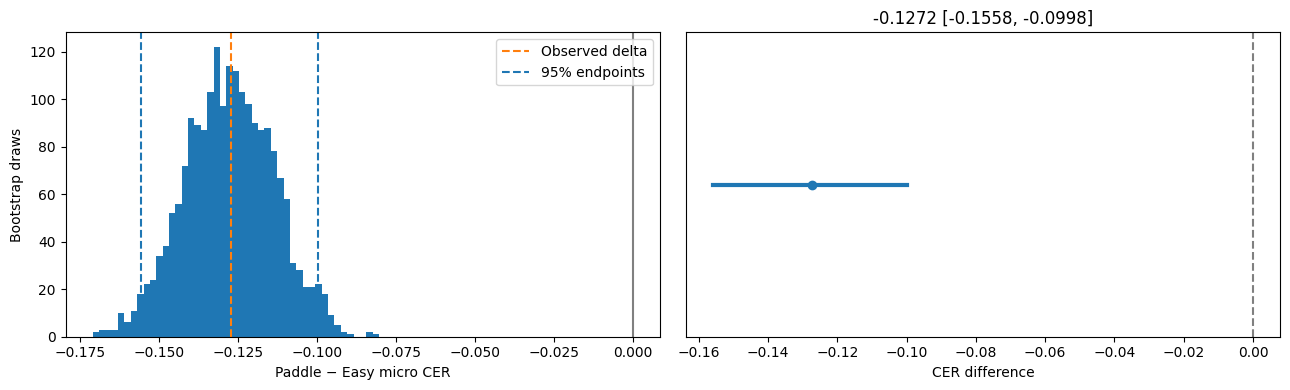

Full tables and figures saved to: /content/drive/MyDrive/OCR/ocr-validation-261013-v1


In [11]:
from experiments.scripts.ocr_comparison_visualization import render_comparison
render_comparison(paired, easy, paddle, summary, OUT)
print('Full tables and figures saved to:', OUT)


## Gửi kết quả để nhận xét

Sau khi hoàn thành, giữ notebook có output và thư mục RUN_ID gồm `paired_full.summary.json`, hai JSONL, identity receipts, cohort features, bảng lỗi và PNG. Nếu Colab ngắt: dừng phiên cũ, reconnect, chạy lại từ đầu với RUN_ID cũ; checkpoint không khớp sẽ dừng và yêu cầu RUN_ID mới. Nếu còn file `<engine>.lock` sau khi tiến trình bị kill, xác nhận phiên cũ đã dừng rồi xóa riêng file lock đó trước khi resume. JSONL hỏng ở dòng cuối do ngắt ghi sẽ bị từ chối, không tự bỏ dữ liệu. Không chỉnh nhãn hoặc chọn mẫu sau khi xem điểm.

Nguồn: [IIIT-CVID mirror, pinned revision](https://huggingface.co/datasets/staghado/IIIT-CVid/tree/8159222f11460bff70bec7990ade19c468755fe4), [EasyOCR 1.7.2](https://pypi.org/project/easyocr/1.7.2/), [PaddleOCR 2.8.1](https://pypi.org/project/paddleocr/2.8.1/).


## Phục hồi lỗi NumPy ABI từ bản notebook cũ (chỉ khi đã gặp lỗi)

Nếu kernel Python 3.13 hiện lỗi `numpy.dtype size changed`, bản cũ đã có ràng buộc NumPy <2 không phù hợp kernel. Không chạy lại cell cài đặt cũ. Chạy cell phục hồi dưới đây sau khi đổi `REPAIR_NATIVE_KERNEL` thành True, sau đó chọn **Runtime → Restart session** và chạy notebook đã cập nhật từ đầu. Restart session giữ file trong /content; không chọn Delete runtime nếu muốn giữ ZIP đã tải. Cell này không thay đổi môi trường OCR Python 3.11 hoặc file dữ liệu/nhãn. Chỉ dùng gói wheel, không build NumPy từ source. Mặc định cell không thực hiện thay đổi.


In [12]:
REPAIR_NATIVE_KERNEL = False  # chỉ bật nếu kernel hiện bị lỗi ABI
if REPAIR_NATIVE_KERNEL:
    if sys.version_info[:2] not in ((3, 10), (3, 11), (3, 12), (3, 13)):
        raise RuntimeError('Recovery pins support Python 3.10–3.13; inspect this runtime first.')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '--upgrade',
        '--force-reinstall', '--no-cache-dir', '--only-binary=:all:',
        'numpy==2.2.6', 'pandas==2.2.3', 'matplotlib==3.10.6', 'Pillow==11.3.0'], check=True)
    raise RuntimeError('Recovery installed. Select Runtime → Restart session now, then rerun from the first cell. Do not keep using this loaded kernel.')
else:
    print('Optional ABI recovery skipped; nothing changed.')


Optional ABI recovery skipped; nothing changed.
